<div style='background: linear-gradient(135deg,#1a1a2e,#16213e,#0f3460); padding:40px; border-radius:16px; text-align:center; margin-bottom:10px'>
  <h1 style='color:#e94560; font-size:2.2em; margin:0'>🧪 Laboratorio de Machine Learning</h1>
  <h2 style='color:#ffffff; font-size:1.4em; margin:10px 0'>Benchmark de 10 Modelos para Predicción de Propiedades Moleculares desde SMILES</h2>
  <p style='color:#a8b2d8; font-size:1em; margin:0'>Lipophilicity · FreeSolv · Toxicidad LD50 en ratas</p>
  <p style='color:#a8b2d8; font-size:0.9em; margin-top:6px'>Edición "artículo científico" — scaffold split · búsqueda de hiperparámetros · tests estadísticos · SHAP</p>
</div>

---

## 🎯 Objetivos de Aprendizaje

Al finalizar este laboratorio serás capaz de:

1. **Entender** qué es SMILES y cómo representar moléculas computacionalmente
2. **Calcular** descriptores moleculares con RDKit a partir de un SMILES
3. **Explorar** tres datasets reales de quimioinformática (EDA)
4. **Aplicar un scaffold split** y explicar por qué es más riguroso que un split aleatorio en QSAR
5. **Construir** un pipeline de ML reutilizable para regresión molecular
6. **Comparar 10 modelos** de 5 familias distintas (lineales, instancia, kernel, ensembles de bagging/boosting, red neuronal) con búsqueda de hiperparámetros
7. **Cuantificar la incertidumbre**: reportar métricas como media ± desviación estándar, no un solo número
8. **Determinar si las diferencias entre modelos son estadísticamente significativas** (Friedman + Wilcoxon)
9. **Interpretar** el mejor modelo de cada dataset con SHAP
10. **Validar correctamente**: Train / Validación / Test, usando Test una sola vez

---

## 📊 Datasets que usaremos

| # | Dataset | Propiedad | Moléculas | Dificultad esperada |
|---|---------|-----------|-----------|--------------------|
| 1 | **Lipophilicity** | LogP (coef. partición octanol/agua) | ~4,200 | 🟢 Fácil — R² ≈ 0.85-0.90 |
| 2 | **FreeSolv** | Energía de solvatación (kcal/mol) | ~643 | 🟡 Medio — dataset pequeño |
| 3 | **LD50_Zhu** | Toxicidad oral en ratas (mg/kg) | ~7,385 | 🔴 Difícil — datos ruidosos |

## 🤖 Los 10 modelos que compararemos

| Familia | Modelos | Idea central |
|---------|---------|---------------|
| Lineales regularizados | Ridge, Lasso, ElasticNet | Relación lineal entre descriptores y target, con penalización L2/L1/ambas |
| Basado en instancias | KNN | Promedia las moléculas más "parecidas" en el espacio de descriptores |
| Kernel | SVR (RBF) | Busca una superficie de decisión con margen de tolerancia ε |
| Ensembles (bagging) | Random Forest, Extra Trees | Combinan muchos árboles entrenados con aleatoriedad |
| Ensembles (boosting) | Gradient Boosting, XGBoost | Árboles secuenciales que corrigen errores del anterior |
| Red neuronal | MLP (feedforward) | Capas densas no lineales entrenadas por backpropagation |

> 💡 **Nota pedagógica:** no existe un modelo que gane siempre ("*no free lunch theorem*"). El objetivo de este laboratorio es que aprendas a comparar modelos de forma **rigurosa y honesta**, no solo a maximizar un número.


---
# 📦 PARTE 0 — Instalación y Fundamentos
---

In [1]:
# ══════════════════════════════════════════════════════
#  CELDA 0.1 — Instalación de dependencias
#  Solo necesario en Google Colab. Ejecutar una vez.
# ══════════════════════════════════════════════════════

!pip install rdkit --quiet
!pip install scikit-learn pandas numpy matplotlib seaborn --quiet
!pip install xgboost shap --quiet
!pip install datasets --quiet

print('✅ Instalación completa')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 33.2 MB/s eta 0:00:00
✅ Instalación completa


In [2]:
# ══════════════════════════════════════════════════════
#  CELDA 0.2 — Importaciones
# ══════════════════════════════════════════════════════

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from rdkit import Chem
from rdkit.Chem import Descriptors, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import loguniform, uniform, randint, friedmanchisquare, wilcoxon

import shap

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('✅ Todas las librerías importadas correctamente')

✅ Todas las librerías importadas correctamente


## ⚙️ Modo de ejecución: rápido vs completo

Este notebook hace **búsqueda de hiperparámetros** para 10 modelos en 3 datasets — con la configuración
completa puede tardar bastante en Colab (especialmente SVR y XGBoost sobre LD50, que tiene ~7,385 moléculas).

- **`FAST_MODE = True`** → pocas iteraciones de búsqueda y pocos folds. Úsalo para verificar que todo
  el pipeline corre sin errores en unos minutos.
- **`FAST_MODE = False`** → configuración "de artículo": más iteraciones, más folds, más semillas.
  Úsalo para generar los resultados finales (puede tardar 20-40+ min en total).

> 📌 Recomendación: corre primero con `FAST_MODE = True` para revisar que todo funcione, y luego
> cambia a `False` antes de generar tu reporte final.

In [3]:
# ══════════════════════════════════════════════════════
#  CELDA 0.3 — Configuración de modo de ejecución
# ══════════════════════════════════════════════════════

FAST_MODE = True   # ← Cambia a False para la corrida final ("de artículo")

N_ITER_SEARCH   = 8   if FAST_MODE else 30     # iteraciones de RandomizedSearchCV
CV_FOLDS        = 3   if FAST_MODE else 5      # folds para la búsqueda y para CV de robustez
SEEDS_ROBUSTEZ  = [42, 7] if FAST_MODE else [42, 7, 123, 2024, 99]   # semillas para robustez

print(f'FAST_MODE        = {FAST_MODE}')
print(f'N_ITER_SEARCH     = {N_ITER_SEARCH}')
print(f'CV_FOLDS          = {CV_FOLDS}')
print(f'SEEDS_ROBUSTEZ    = {SEEDS_ROBUSTEZ}')

FAST_MODE        = True
N_ITER_SEARCH     = 8
CV_FOLDS          = 3
SEEDS_ROBUSTEZ    = [42, 7]


## 🔬 ¿Qué es SMILES?

**SMILES** (Simplified Molecular Input Line Entry System) representa moléculas como texto.
Es el formato estándar para intercambiar estructuras químicas en bases de datos y ML.

| Molécula | SMILES | LogP aprox. |
|----------|--------|-------------|
| Aspirina | `CC(=O)Oc1ccccc1C(=O)O` | 1.19 |
| Cafeína | `Cn1cnc2c1c(=O)n(c(=O)n2C)C` | -0.07 |
| Ibuprofeno | `CC(C)Cc1ccc(cc1)C(C)C(=O)O` | 3.97 |
| Colesterol | `CC(C)CCCC(C)C1CCC2C1(CCC3C2CC=C4C3(CCC(C4)O)C)C` | 8.74 |

> 🧠 **Regla de Lipinski:** Un fármaco oral ideal tiene LogP entre 0 y 5, MW ≤ 500, HBD ≤ 5, HBA ≤ 10

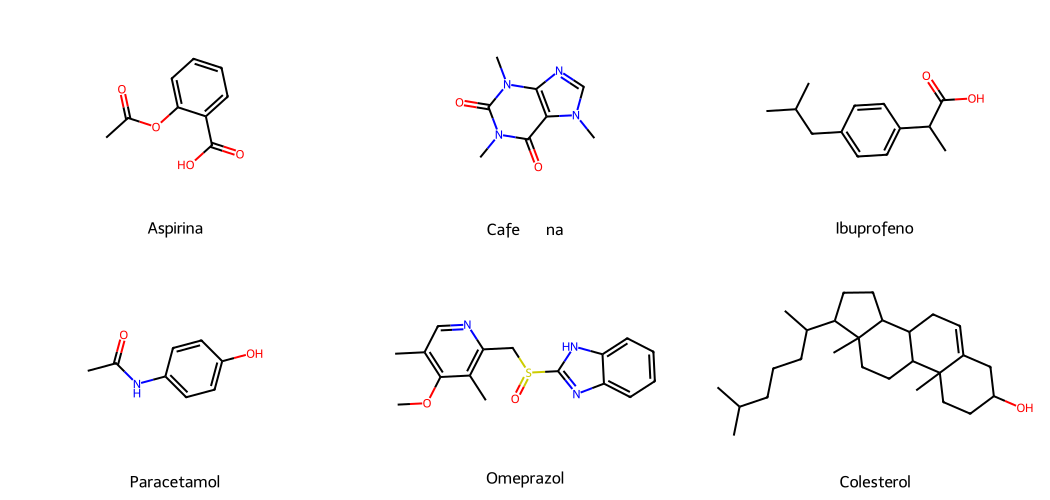

In [4]:
# ══════════════════════════════════════════════════════
#  CELDA 0.4 — Visualizar moléculas desde SMILES
# ══════════════════════════════════════════════════════

moléculas_ejemplo = {
    'Aspirina':    'CC(=O)Oc1ccccc1C(=O)O',
    'Cafeína':     'Cn1cnc2c1c(=O)n(c(=O)n2C)C',
    'Ibuprofeno':  'CC(C)Cc1ccc(cc1)C(C)C(=O)O',
    'Paracetamol': 'CC(=O)Nc1ccc(O)cc1',
    'Omeprazol':   'CC1=CN=C(C(=C1OC)C)CS(=O)C2=NC3=CC=CC=C3N2',
    'Colesterol':  'CC(C)CCCC(C)C1CCC2C1(CCC3C2CC=C4C3(CCC(C4)O)C)C',
}

mols   = [Chem.MolFromSmiles(s) for s in moléculas_ejemplo.values()]
labels = list(moléculas_ejemplo.keys())

img = Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(350, 250), legends=labels)
img

## 🧩 Descriptores moleculares y scaffold

Vamos a calcular dos cosas distintas a partir de cada SMILES:

1. **19 descriptores moleculares** (features numéricas) — igual que en la versión anterior del laboratorio.
2. El **scaffold de Bemis-Murcko** (el "esqueleto" estructural de la molécula, quitando cadenas
   laterales) — lo usaremos en la Parte 2 para hacer un split más riguroso que el aleatorio.

In [5]:
# ══════════════════════════════════════════════════════
#  CELDA 0.5 — Funciones maestras: descriptores y scaffold
#  Se reutilizarán para los 3 datasets
# ══════════════════════════════════════════════════════

FEATURE_NAMES = [
    'MW', 'LogP_rdkit', 'TPSA', 'HBD', 'HBA', 'RotBonds',
    'ArRings', 'HeavyAtoms', 'RingCount', 'FractionCSP3',
    'MolMR', 'Chi0', 'Chi1', 'Kappa1', 'Kappa2',
    'BertzCT', 'MaxPartialCharge', 'MinPartialCharge', 'NumAliphRings'
]

def calcular_descriptores(smiles):
    """Calcula 19 descriptores moleculares a partir de un SMILES.
    Retorna None si el SMILES es inválido."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    try:
        return {
            'MW':               Descriptors.MolWt(mol),
            'LogP_rdkit':       Descriptors.MolLogP(mol),
            'TPSA':             Descriptors.TPSA(mol),
            'HBD':              Descriptors.NumHDonors(mol),
            'HBA':              Descriptors.NumHAcceptors(mol),
            'RotBonds':         Descriptors.NumRotatableBonds(mol),
            'ArRings':          Descriptors.NumAromaticRings(mol),
            'HeavyAtoms':       mol.GetNumHeavyAtoms(),
            'RingCount':        Descriptors.RingCount(mol),
            'FractionCSP3':     Descriptors.FractionCSP3(mol),
            'MolMR':            Descriptors.MolMR(mol),
            'Chi0':             Descriptors.Chi0(mol),
            'Chi1':             Descriptors.Chi1(mol),
            'Kappa1':           Descriptors.Kappa1(mol),
            'Kappa2':           Descriptors.Kappa2(mol),
            'BertzCT':          Descriptors.BertzCT(mol),
            'MaxPartialCharge': Descriptors.MaxPartialCharge(mol),
            'MinPartialCharge': Descriptors.MinPartialCharge(mol),
            'NumAliphRings':    Descriptors.NumAliphaticRings(mol),
        }
    except Exception:
        return None


def obtener_scaffold(smiles):
    """Retorna el SMILES del scaffold de Bemis-Murcko de una molécula.
    Retorna None si el SMILES es inválido."""
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return None
        scaffold = MurckoScaffold.GetScaffoldForMol(mol)
        return Chem.MolToSmiles(scaffold)
    except Exception:
        return None


def smiles_list_to_features(smiles_list, target_list, dataset_name=''):
    """Convierte listas de SMILES y targets en un DataFrame con descriptores
    y scaffold. Descarta moléculas con SMILES inválido."""
    rows, targets, validos, scaffolds = [], [], [], []
    for smi, tgt in zip(smiles_list, target_list):
        desc = calcular_descriptores(str(smi))
        if desc is not None and tgt is not None and not np.isnan(float(tgt)):
            rows.append(desc)
            targets.append(float(tgt))
            validos.append(smi)
            scaffolds.append(obtener_scaffold(str(smi)))
    df_feat = pd.DataFrame(rows, columns=FEATURE_NAMES)
    df_feat['target']   = targets
    df_feat['smiles']   = validos
    df_feat['scaffold'] = scaffolds
    print(f'  [{dataset_name}] Moléculas procesadas: {len(df_feat):,}  '
          f'(descartadas: {len(smiles_list) - len(df_feat)})  |  '
          f'scaffolds únicos: {df_feat["scaffold"].nunique():,}')
    return df_feat


# Demostración con la aspirina
aspirina_desc = calcular_descriptores('CC(=O)Oc1ccccc1C(=O)O')
print('📋 Descriptores de la Aspirina:')
for k, v in aspirina_desc.items():
    print(f'   {k:22s}: {v:.4f}')
print(f'\n🦴 Scaffold de la Aspirina: {obtener_scaffold("CC(=O)Oc1ccccc1C(=O)O")}')

📋 Descriptores de la Aspirina:
   MW                    : 180.1590
   LogP_rdkit            : 1.3101
   TPSA                  : 63.6000
   HBD                   : 1.0000
   HBA                   : 3.0000
   RotBonds              : 2.0000
   ArRings               : 1.0000
   HeavyAtoms            : 13.0000
   RingCount             : 1.0000
   FractionCSP3          : 0.1111
   MolMR                 : 44.7103
   Chi0                  : 9.8449
   Chi1                  : 6.1091
   Kappa1                : 9.2496
   Kappa2                : 3.7093
   BertzCT               : 343.2229
   MaxPartialCharge      : 0.3390
   MinPartialCharge      : -0.4775
   NumAliphRings         : 0.0000

🦴 Scaffold de la Aspirina: c1ccccc1


---
# 📗 PARTE 1 — Carga y Exploración de los 3 Datasets (EDA)
---

## 🔹 1A — Lipophilicity (LogP)

**¿Qué es LogP?** Mide qué tan bien se disuelve una molécula en grasa vs. en agua.
- LogP **bajo** (< 0): muy soluble en agua, cruza mal membranas
- LogP **alto** (> 5): muy lipofílico, acumulación en tejido graso

**Fuente:** MoleculeNet / AstraZeneca · URL: `deepchemdata.s3-us-west-1.amazonaws.com`

In [6]:
# ══════════════════════════════════════════════════════
#  CELDA 1.1 — Cargar y procesar Lipophilicity
# ══════════════════════════════════════════════════════

URL_LIPO = 'https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/Lipophilicity.csv'

print('⏳ Descargando Lipophilicity...')
df_lipo_raw = pd.read_csv(URL_LIPO)
print(f'✅ Cargado: {df_lipo_raw.shape[0]:,} filas | Columnas: {list(df_lipo_raw.columns)}')
display(df_lipo_raw.head(4))

print('\n⏳ Calculando descriptores y scaffolds (~1 min)...')
df_lipo = smiles_list_to_features(
    df_lipo_raw['smiles'].tolist(), df_lipo_raw['exp'].tolist(), 'Lipophilicity')

print('\n📊 Target — LogP experimental:')
print(df_lipo['target'].describe().round(3).to_string())

⏳ Descargando Lipophilicity...
✅ Cargado: 4,200 filas | Columnas: ['CMPD_CHEMBLID', 'exp', 'smiles']


,CMPD_CHEMBLID,exp,smiles
0,CHEMBL596271,3.54,Cn1c(CN2CCN(CC2)c3ccc(Cl)cc3)nc4ccccc14
1,CHEMBL1951080,-1.18,COc1cc(OC)c(cc1NC(=O)CSCC(=O)O)S(=O)(=O)N2C(C)...
2,CHEMBL1771,3.69,COC(=O)[C@@H](N1CCc2sccc2C1)c3ccccc3Cl
3,CHEMBL234951,3.37,OC[C@H](O)CN1C(=O)C(Cc2ccccc12)NC(=O)c3cc4cc(C...



⏳ Calculando descriptores y scaffolds (~1 min)...
  [Lipophilicity] Moléculas procesadas: 4,200  (descartadas: 0)  |  scaffolds únicos: 2,444

📊 Target — LogP experimental:
count    4200.000
mean        2.186
std         1.203
min        -1.500
25%         1.410
50%         2.360
75%         3.100
max         4.500


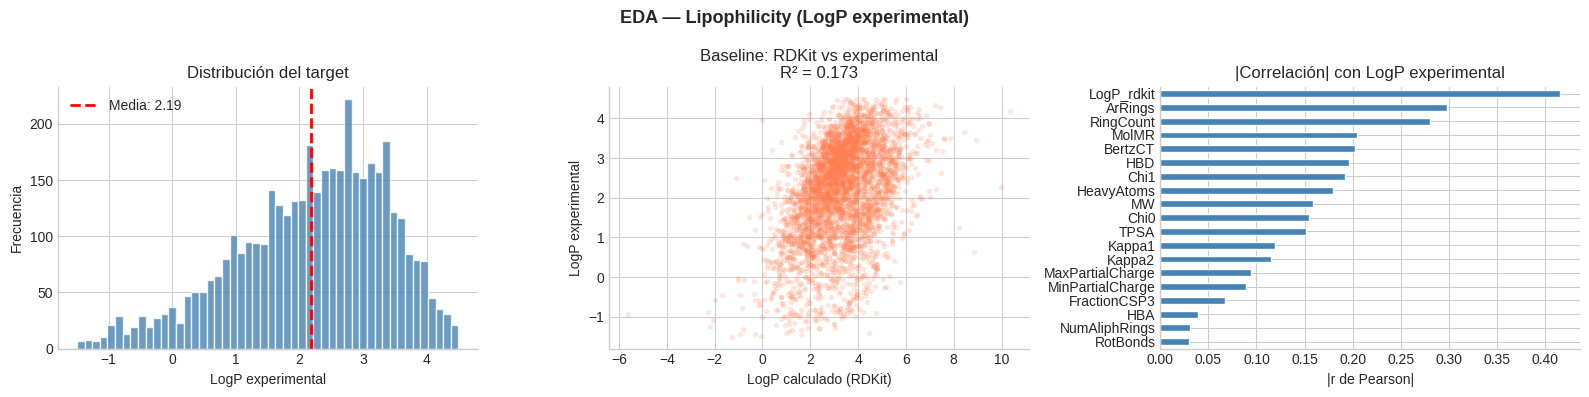


💡 El LogP calculado por RDKit ya explica ~17% de la varianza — es un fuerte predictor por sí solo. Veremos si los modelos de ML lo superan.
🦴 Diversidad estructural: 2,444 scaffolds únicos para 4,200 moléculas.


In [7]:
# ══════════════════════════════════════════════════════
#  CELDA 1.2 — EDA visual Lipophilicity
# ══════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('EDA — Lipophilicity (LogP experimental)', fontweight='bold', fontsize=13)

ax = axes[0]
ax.hist(df_lipo['target'], bins=50, color='steelblue', alpha=0.8, edgecolor='white')
ax.axvline(df_lipo['target'].mean(), color='red', linestyle='--', linewidth=2,
           label=f"Media: {df_lipo['target'].mean():.2f}")
ax.set_xlabel('LogP experimental'); ax.set_ylabel('Frecuencia')
ax.set_title('Distribución del target'); ax.legend()
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

ax = axes[1]
ax.scatter(df_lipo['LogP_rdkit'], df_lipo['target'], alpha=0.15, s=8, color='coral')
r2_base = np.corrcoef(df_lipo['LogP_rdkit'], df_lipo['target'])[0,1]**2
ax.set_xlabel('LogP calculado (RDKit)'); ax.set_ylabel('LogP experimental')
ax.set_title(f'Baseline: RDKit vs experimental\nR² = {r2_base:.3f}')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

ax = axes[2]
corrs = df_lipo[FEATURE_NAMES + ['target']].corr()['target'].drop('target').abs().sort_values()
corrs.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('|Correlación| con LogP experimental'); ax.set_xlabel('|r de Pearson|')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.tight_layout(); plt.show()
print(f'\n💡 El LogP calculado por RDKit ya explica ~{r2_base:.0%} de la varianza — '
      f'es un fuerte predictor por sí solo. Veremos si los modelos de ML lo superan.')
print(f'🦴 Diversidad estructural: {df_lipo["scaffold"].nunique():,} scaffolds únicos '
      f'para {len(df_lipo):,} moléculas.')

## 🔹 1B — FreeSolv (Energía de solvatación)

**¿Qué es ΔG de hidratación?** Energía cuando una molécula pasa de gas a disolverse en agua.
Valores más negativos = molécula más soluble en agua.

**Desafío:** solo ~643 moléculas → usaremos **cross-validation** para compensar.

**Fuente:** Mobley & Guthrie, J. Comput. Aided Mol. Des. (2014) · URL: `deepchemdata.s3-us-west-1.amazonaws.com`

In [8]:
# ══════════════════════════════════════════════════════
#  CELDA 1.3 — Cargar y procesar FreeSolv
# ══════════════════════════════════════════════════════

URL_FREESOLV = 'https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/SAMPL.csv'

print('⏳ Descargando FreeSolv...')
df_freesolv_raw = pd.read_csv(URL_FREESOLV)
print(f'✅ Cargado: {df_freesolv_raw.shape[0]:,} filas | Columnas: {list(df_freesolv_raw.columns)}')
display(df_freesolv_raw.head(4))

print('\n⏳ Calculando descriptores y scaffolds...')
df_freesolv = smiles_list_to_features(
    df_freesolv_raw['smiles'].tolist(), df_freesolv_raw['expt'].tolist(), 'FreeSolv')

print('\n📊 Target — ΔG hidratación (kcal/mol):')
print(df_freesolv['target'].describe().round(3).to_string())
print(f'\n⚠️  Solo {len(df_freesolv)} moléculas — dataset muy pequeño para ML.')

⏳ Descargando FreeSolv...
✅ Cargado: 642 filas | Columnas: ['iupac', 'smiles', 'expt', 'calc']


,iupac,smiles,expt,calc
0,"4-methoxy-N,N-dimethyl-benzamide",CN(C)C(=O)c1ccc(cc1)OC,-11.01,-9.625
1,methanesulfonyl chloride,CS(=O)(=O)Cl,-4.87,-6.219
2,3-methylbut-1-ene,CC(C)C=C,1.83,2.452
3,2-ethylpyrazine,CCc1cnccn1,-5.45,-5.809



⏳ Calculando descriptores y scaffolds...
  [FreeSolv] Moléculas procesadas: 642  (descartadas: 0)  |  scaffolds únicos: 63

📊 Target — ΔG hidratación (kcal/mol):
count    642.000
mean      -3.803
std        3.848
min      -25.470
25%       -5.728
50%       -3.530
75%       -1.215
max        3.430

⚠️  Solo 642 moléculas — dataset muy pequeño para ML.


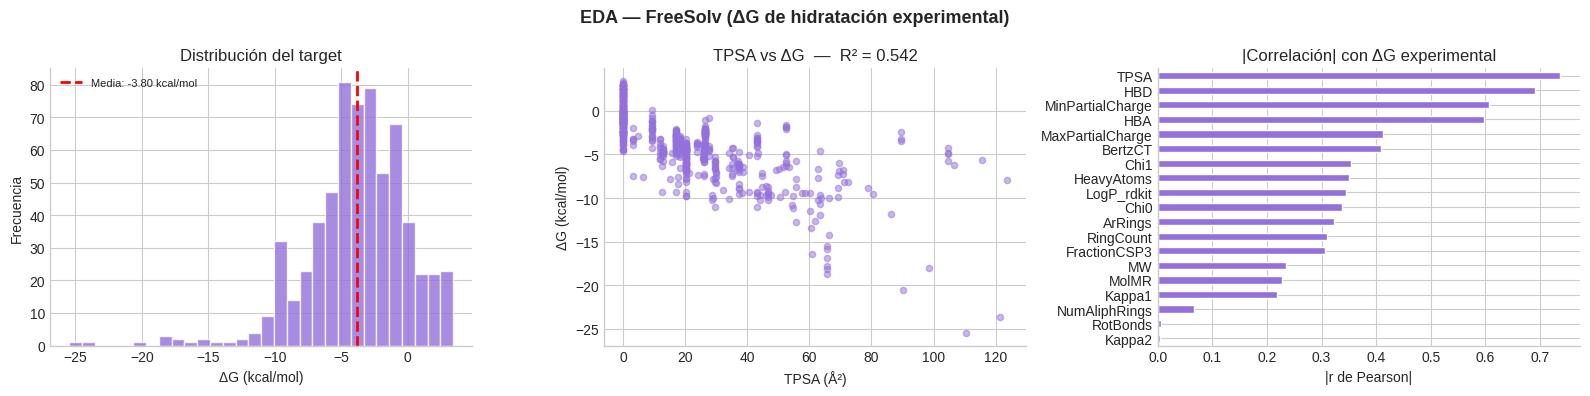

🦴 Diversidad estructural: 63 scaffolds únicos para 642 moléculas.


In [9]:
# ══════════════════════════════════════════════════════
#  CELDA 1.4 — EDA visual FreeSolv
# ══════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('EDA — FreeSolv (ΔG de hidratación experimental)', fontweight='bold', fontsize=13)

ax = axes[0]
ax.hist(df_freesolv['target'], bins=30, color='mediumpurple', alpha=0.8, edgecolor='white')
ax.axvline(df_freesolv['target'].mean(), color='red', linestyle='--', linewidth=2,
           label=f"Media: {df_freesolv['target'].mean():.2f} kcal/mol")
ax.set_xlabel('ΔG (kcal/mol)'); ax.set_ylabel('Frecuencia')
ax.set_title('Distribución del target'); ax.legend(fontsize=8)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

ax = axes[1]
ax.scatter(df_freesolv['TPSA'], df_freesolv['target'], alpha=0.5, s=20, color='mediumpurple')
r2_tpsa = np.corrcoef(df_freesolv['TPSA'], df_freesolv['target'])[0,1]**2
ax.set_xlabel('TPSA (Å²)'); ax.set_ylabel('ΔG (kcal/mol)')
ax.set_title(f'TPSA vs ΔG  —  R² = {r2_tpsa:.3f}')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

ax = axes[2]
corrs_fs = df_freesolv[FEATURE_NAMES + ['target']].corr()['target'].drop('target').abs().sort_values()
corrs_fs.plot(kind='barh', ax=ax, color='mediumpurple', edgecolor='white')
ax.set_title('|Correlación| con ΔG experimental'); ax.set_xlabel('|r de Pearson|')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.tight_layout(); plt.show()
print(f'🦴 Diversidad estructural: {df_freesolv["scaffold"].nunique():,} scaffolds únicos '
      f'para {len(df_freesolv):,} moléculas.')

## 🔹 1C — LD50 Zhu (Toxicidad oral en ratas)

**¿Qué es LD50?** La Dosis Letal 50: cantidad de sustancia que mata al 50% de los animales.
- LD50 **alto** (> 5,000 mg/kg): poco tóxico — sal de mesa ≈ 3,000 mg/kg
- LD50 **bajo** (< 50 mg/kg): muy tóxico — arsénico ≈ 15 mg/kg

**¿Por qué log₁₀(LD50)?** Los valores van de 0.5 a 15,000 mg/kg (5 órdenes de magnitud).
La transformación logarítmica estabiliza la escala y mejora el aprendizaje.

**Fuente:** Zhu et al., Chem. Res. Toxicol. (2009) · Cargado desde Hugging Face (Parquet)

In [10]:
# ══════════════════════════════════════════════════════
#  CELDA 1.5 — Cargar LD50 desde Hugging Face (Parquet)
# ══════════════════════════════════════════════════════

from datasets import load_dataset

print('⏳ Descargando LD50 desde Hugging Face...')
ds = load_dataset("scikit-fingerprints/TDC_ld50_zhu")  # split por defecto = 'train'
df_ld50_raw = ds["train"].to_pandas()
print(f'✅ Cargado: {df_ld50_raw.shape[0]:,} filas | Columnas: {list(df_ld50_raw.columns)}')
display(df_ld50_raw.head(4))

log_ld50 = np.log10(df_ld50_raw['Y'].astype(float))

print('\n⏳ Calculando descriptores y scaffolds (~2 min)...')
df_ld50 = smiles_list_to_features(
    df_ld50_raw['SMILES'].tolist(), log_ld50.tolist(), 'LD50_Zhu')

print('\n📊 Target — log₁₀(LD50) [mg/kg]:')
print(df_ld50['target'].describe().round(3).to_string())
print('\n💡 Referencia: log₁₀(50)=1.70 | log₁₀(500)=2.70 | log₁₀(5000)=3.70')

⏳ Descargando LD50 desde Hugging Face...


README.md:   0%|          | 0.00/1.55k [00:00<?, ?B/s]

tdc_ld50_zhu.csv:   0%|          | 0.00/270k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7385 [00:00<?, ? examples/s]

✅ Cargado: 7,385 filas | Columnas: ['SMILES', 'Y']


,SMILES,Y
0,[O-][N+](=Nc1ccccc1)c1ccccc1,2.505
1,BrC(Br)Br,2.343
2,C=CBr,2.330
3,Brc1ccc(-c2ccc(Br)c(Br)c2Br)c(Br)c1Br,1.465



⏳ Calculando descriptores y scaffolds (~2 min)...
  [LD50_Zhu] Moléculas procesadas: 7,384  (descartadas: 1)  |  scaffolds únicos: 1,677

📊 Target — log₁₀(LD50) [mg/kg]:
count    7384.000
mean        0.376
std         0.161
min        -0.536
25%         0.269
50%         0.374
75%         0.482
max         1.009

💡 Referencia: log₁₀(50)=1.70 | log₁₀(500)=2.70 | log₁₀(5000)=3.70


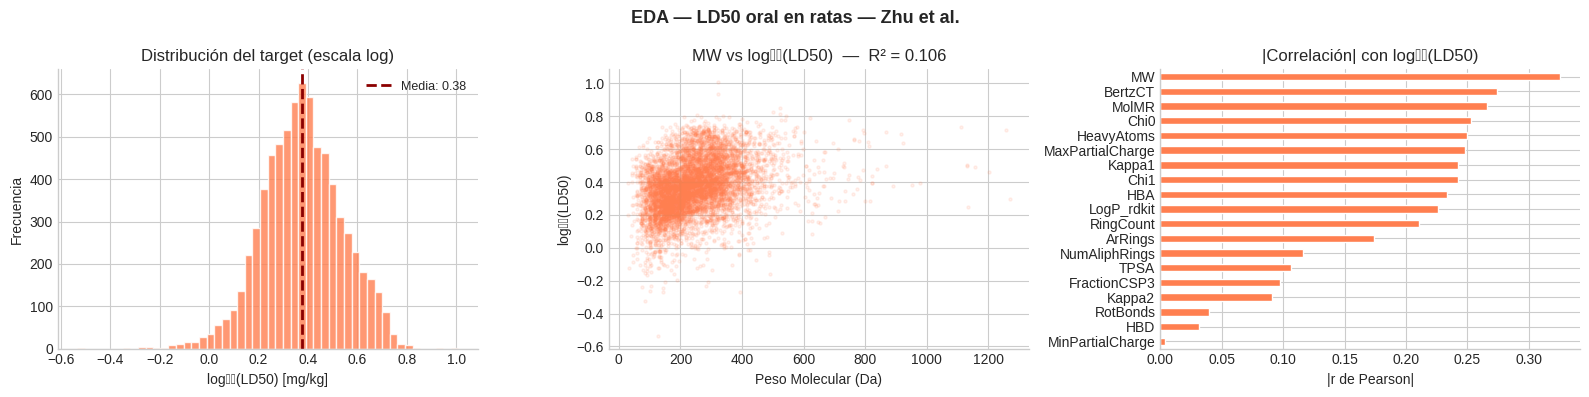

⚠️  Correlaciones bajas → la toxicidad depende de mecanismos biológicos que los descriptores 2D no capturan del todo.
🦴 Diversidad estructural: 1,677 scaffolds únicos para 7,384 moléculas.


In [11]:
# ══════════════════════════════════════════════════════
#  CELDA 1.6 — EDA visual LD50
# ══════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('EDA — LD50 oral en ratas — Zhu et al.', fontweight='bold', fontsize=13)

ax = axes[0]
ax.hist(df_ld50['target'], bins=50, color='coral', alpha=0.8, edgecolor='white')
ax.axvline(df_ld50['target'].mean(), color='darkred', linestyle='--', linewidth=2,
           label=f"Media: {df_ld50['target'].mean():.2f}")
ax.set_xlabel('log₁₀(LD50) [mg/kg]'); ax.set_ylabel('Frecuencia')
ax.set_title('Distribución del target (escala log)'); ax.legend(fontsize=9)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

ax = axes[1]
ax.scatter(df_ld50['MW'], df_ld50['target'], alpha=0.1, s=5, color='coral')
r2_mw = np.corrcoef(df_ld50['MW'], df_ld50['target'])[0,1]**2
ax.set_xlabel('Peso Molecular (Da)'); ax.set_ylabel('log₁₀(LD50)')
ax.set_title(f'MW vs log₁₀(LD50)  —  R² = {r2_mw:.3f}')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

ax = axes[2]
corrs_ld = df_ld50[FEATURE_NAMES + ['target']].corr()['target'].drop('target').abs().sort_values()
corrs_ld.plot(kind='barh', ax=ax, color='coral', edgecolor='white')
ax.set_title('|Correlación| con log₁₀(LD50)'); ax.set_xlabel('|r de Pearson|')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.tight_layout(); plt.show()
print('⚠️  Correlaciones bajas → la toxicidad depende de mecanismos biológicos '
      'que los descriptores 2D no capturan del todo.')
print(f'🦴 Diversidad estructural: {df_ld50["scaffold"].nunique():,} scaffolds únicos '
      f'para {len(df_ld50):,} moléculas.')

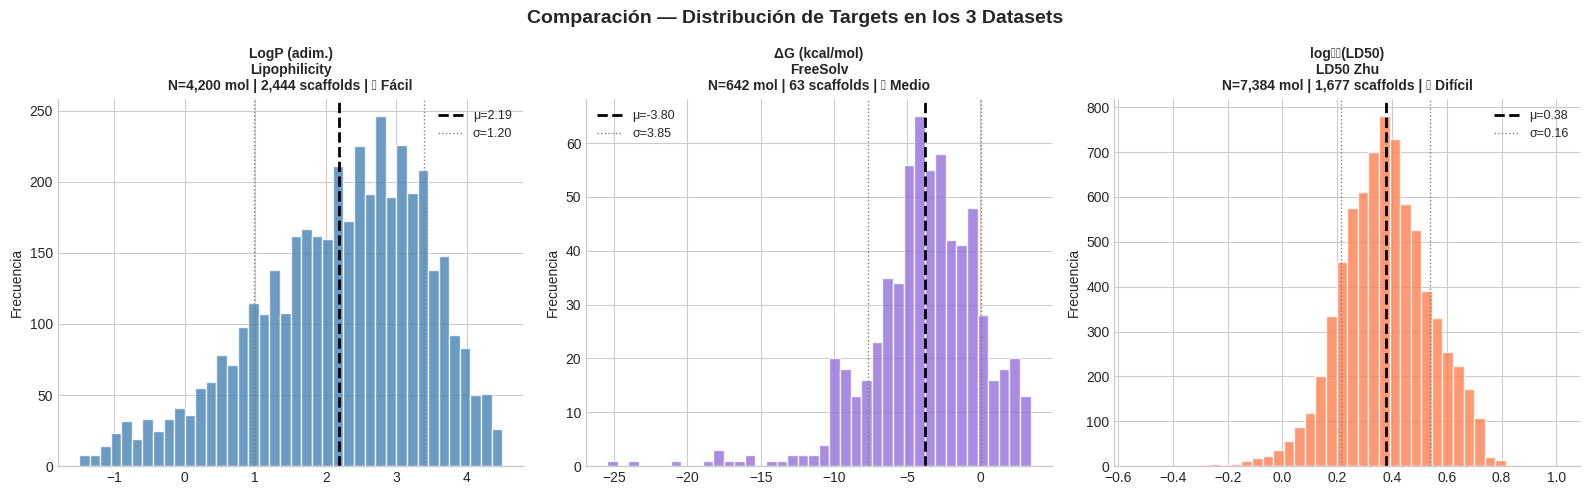

,Dataset,N moléculas,N scaffolds,Media target,Std target
0,Lipophilicity (LogP),4200,2444,2.19,1.20
1,FreeSolv (ΔG),642,63,-3.80,3.85
2,LD50 Zhu (log₁₀),7384,1677,0.38,0.16


In [12]:
# ══════════════════════════════════════════════════════
#  CELDA 1.7 — Panel comparativo de los 3 datasets
# ══════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Comparación — Distribución de Targets en los 3 Datasets',
             fontweight='bold', fontsize=14)

datasets_plot = [
    (df_lipo,     'LogP (adim.)\nLipophilicity',    'steelblue',    '🟢 Fácil'),
    (df_freesolv, 'ΔG (kcal/mol)\nFreeSolv',        'mediumpurple', '🟡 Medio'),
    (df_ld50,     'log₁₀(LD50)\nLD50 Zhu',          'coral',        '🔴 Difícil'),
]

for ax, (df, name, color, nivel) in zip(axes, datasets_plot):
    t = df['target']
    ax.hist(t, bins=40, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(t.mean(), color='black', linestyle='--', lw=2, label=f'μ={t.mean():.2f}')
    ax.axvline(t.mean() - t.std(), color='gray', linestyle=':', lw=1)
    ax.axvline(t.mean() + t.std(), color='gray', linestyle=':', lw=1, label=f'σ={t.std():.2f}')
    ax.set_title(f'{name}\nN={len(df):,} mol | {df["scaffold"].nunique():,} scaffolds | {nivel}',
                 fontweight='bold', fontsize=10)
    ax.set_ylabel('Frecuencia'); ax.legend(fontsize=9)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.tight_layout(); plt.show()

resumen = pd.DataFrame({
    'Dataset':        ['Lipophilicity (LogP)', 'FreeSolv (ΔG)', 'LD50 Zhu (log₁₀)'],
    'N moléculas':    [len(df_lipo), len(df_freesolv), len(df_ld50)],
    'N scaffolds':    [df_lipo['scaffold'].nunique(), df_freesolv['scaffold'].nunique(), df_ld50['scaffold'].nunique()],
    'Media target':   [df_lipo['target'].mean(), df_freesolv['target'].mean(), df_ld50['target'].mean()],
    'Std target':     [df_lipo['target'].std(), df_freesolv['target'].std(), df_ld50['target'].std()],
})
display(resumen.round(2))

---
# 📙 PARTE 2 — Pipeline ML Reutilizable (con Scaffold Split)
---

## Estrategia de División de Datos

```
╔══════════════════════════════════════════════════════════╗
║  Dataset completo (100%)                                 ║
║  │                                                       ║
║  ├── 🟦 Train   (70%) → el modelo APRENDE de aquí        ║
║  ├── 🟨 Val     (15%) → ajustamos y comparamos modelos   ║
║  └── 🟥 Test    (15%) → evaluación FINAL (¡una sola vez!)║
╚══════════════════════════════════════════════════════════╝
```

> ⚠️ **Regla de oro:** El **Test** nunca se usa para tomar decisiones de diseño.
> Usarlo más de una vez = **data leakage** = métricas optimistas que no generalizan.

## 🦴 ¿Por qué *scaffold split* y no split aleatorio?

En un split **aleatorio**, moléculas muy parecidas (mismo núcleo/scaffold, distintos sustituyentes)
pueden terminar repartidas entre train y test. El modelo "ve" prácticamente la misma molécula durante
el entrenamiento y le resulta trivial predecir a su "gemela" en test → el R² de test queda **inflado**
y no refleja qué tan bien generalizaría el modelo a moléculas *realmente* nuevas.

El **scaffold split** (Bemis-Murcko) agrupa las moléculas por su "esqueleto" estructural y asigna
esqueletos *completos* a train/val/test — nunca partiéndolos. Ninguna molécula de test comparte
scaffold con una de train. Es una evaluación mucho más realista del poder de generalización, y es el
estándar de facto en benchmarks de descubrimiento de fármacos como MoleculeNet.

> 📌 Para no perder de vista el efecto, más abajo comparamos empíricamente **random split vs.
> scaffold split** en Lipophilicity antes de seguir con el resto del laboratorio.

In [13]:
# ══════════════════════════════════════════════════════
#  CELDA 2.1 — Función: scaffold split
# ══════════════════════════════════════════════════════

def scaffold_split(df_features, test_size=0.15, val_size=0.15, random_state=42):
    """
    Divide un DataFrame en Train/Val/Test agrupando por scaffold de Bemis-Murcko.
    Todas las moléculas de un mismo scaffold caen en el MISMO subconjunto.
    Retorna arrays de índices posicionales (sobre df_features.reset_index(drop=True)).
    """
    df = df_features.reset_index(drop=True)
    rng = np.random.RandomState(random_state)

    grupos = df.groupby('scaffold').indices          # {scaffold: [idx,...]}
    claves = list(grupos.keys())
    # Barajar scaffolds enteros (no moléculas individuales)
    rng.shuffle(claves)

    n_total      = len(df)
    n_test_meta  = int(round(n_total * test_size))
    n_val_meta   = int(round(n_total * val_size))

    test_idx, val_idx, train_idx = [], [], []
    for clave in claves:
        idx = list(grupos[clave])
        if len(test_idx) < n_test_meta:
            test_idx.extend(idx)
        elif len(val_idx) < n_val_meta:
            val_idx.extend(idx)
        else:
            train_idx.extend(idx)

    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


def preparar_dataset(df_features, test_size=0.15, val_size=0.15, random_state=42,
                      metodo='scaffold'):
    """
    Limpia, divide (scaffold o random) y normaliza un dataset de descriptores.
    ⚠️ El StandardScaler se ajusta SOLO en Train.
    """
    df_clean = df_features[FEATURE_NAMES + ['target', 'scaffold']].dropna().reset_index(drop=True)
    X = df_clean[FEATURE_NAMES].values
    y = df_clean['target'].values

    if metodo == 'scaffold':
        train_idx, val_idx, test_idx = scaffold_split(
            df_clean, test_size=test_size, val_size=val_size, random_state=random_state)
    elif metodo == 'random':
        idx_all = np.arange(len(df_clean))
        trainval_idx, test_idx = train_test_split(
            idx_all, test_size=test_size, random_state=random_state)
        val_frac = val_size / (1 - test_size)
        train_idx, val_idx = train_test_split(
            trainval_idx, test_size=val_frac, random_state=random_state)
    else:
        raise ValueError("metodo debe ser 'scaffold' o 'random'")

    X_train, y_train = X[train_idx], y[train_idx]
    X_val,   y_val   = X[val_idx],   y[val_idx]
    X_test,  y_test  = X[test_idx],  y[test_idx]

    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_val_sc   = scaler.transform(X_val)
    X_test_sc  = scaler.transform(X_test)

    n = len(y)
    print(f'  División ({metodo}):')
    print(f'    🟦 Train : {len(y_train):>5,} ({len(y_train)/n:.0%})')
    print(f'    🟨 Val   : {len(y_val):>5,}  ({len(y_val)/n:.0%})')
    print(f'    🟥 Test  : {len(y_test):>5,}  ({len(y_test)/n:.0%})')

    return {
        'X_train': X_train_sc, 'y_train': y_train,
        'X_val':   X_val_sc,   'y_val':   y_val,
        'X_test':  X_test_sc,  'y_test':  y_test,
        'scaler':  scaler,
        'X_train_raw': X_train,
        'X_trainval_raw': np.vstack([X_train, X_val]),
        'y_trainval':     np.concatenate([y_train, y_val]),
    }

print('✅ Funciones scaffold_split() y preparar_dataset() listas')

✅ Funciones scaffold_split() y preparar_dataset() listas


### 🔍 Demostración empírica: random split vs. scaffold split

Antes de seguir, comprobemos el efecto con un modelo simple (Ridge) sobre Lipophilicity. Si el R²
de validación cae notablemente al pasar de random a scaffold split, es evidencia de que el split
aleatorio estaba dando una imagen demasiado optimista.

In [14]:
# ══════════════════════════════════════════════════════
#  CELDA 2.2 — Comparación empírica: random vs scaffold split
# ══════════════════════════════════════════════════════

resultados_split = []
for metodo in ['random', 'scaffold']:
    print(f'\n--- Split: {metodo} ---')
    splits_tmp = preparar_dataset(df_lipo, random_state=RANDOM_STATE, metodo=metodo)
    modelo_tmp = Ridge(alpha=1.0)
    modelo_tmp.fit(splits_tmp['X_train'], splits_tmp['y_train'])
    r2_tmp = r2_score(splits_tmp['y_val'], modelo_tmp.predict(splits_tmp['X_val']))
    resultados_split.append({'Split': metodo, 'R2_val (Ridge)': r2_tmp})

df_split_comp = pd.DataFrame(resultados_split).set_index('Split')
display(df_split_comp.round(4))

diferencia = df_split_comp.loc['random', 'R2_val (Ridge)'] - df_split_comp.loc['scaffold', 'R2_val (Ridge)']
print(f'\n💡 Diferencia (random − scaffold) = {diferencia:+.4f}')
print('   Si es positiva y notable, confirma que el split aleatorio sobreestima la generalización.')
print('   A partir de aquí, TODO el laboratorio usa scaffold split.')


--- Split: random ---
  División (random):
    🟦 Train : 2,939 (70%)
    🟨 Val   :   630  (15%)
    🟥 Test  :   630  (15%)

--- Split: scaffold ---
  División (scaffold):
    🟦 Train : 2,939 (70%)
    🟨 Val   :   630  (15%)
    🟥 Test  :   630  (15%)


,R2_val (Ridge)
Split,
random,0.2845
scaffold,0.3566



💡 Diferencia (random − scaffold) = -0.0721
   Si es positiva y notable, confirma que el split aleatorio sobreestima la generalización.
   A partir de aquí, TODO el laboratorio usa scaffold split.


### 📌 ¿Qué aprendimos?
- El **scaffold split** suele dar un R² igual o menor que el random split — y esa diferencia es
  justamente el "self-engaño" que evitamos.
- En un artículo científico o en un flujo real de descubrimiento de fármacos, reportar solo el
  número optimista del random split sería **engañoso**: el modelo se probará con moléculas de
  scaffolds nuevos en el mundo real, no con "gemelas" de las de entrenamiento.

---

---
# 📕 PARTE 3 — Los 10 Modelos y Búsqueda de Hiperparámetros
---

## 🧠 Teoría breve por familia de modelos

| Familia | Modelos | Supuestos / cómo funciona | Cuándo brilla | Cuándo falla |
|---|---|---|---|---|
| **Lineales regularizados** | Ridge, Lasso, ElasticNet | Relación lineal entre descriptores y target. Ridge penaliza L2 (reduce coeficientes), Lasso penaliza L1 (los lleva a cero → selección de variables), ElasticNet combina ambas. | Relación aprox. lineal, features correlacionadas (ej. LogP) | Relaciones fuertemente no lineales |
| **Basado en instancias** | KNN | Promedia el target de las *k* moléculas más cercanas en el espacio de descriptores normalizado. No asume forma funcional. | Vecindarios densos y bien poblados | Alta dimensionalidad, datasets pequeños o dispersos |
| **Kernel** | SVR (RBF) | Busca una superficie de decisión que mantenga los errores dentro de un margen de tolerancia ε. | Datasets medianos, robusto a outliers moderados | Escala mal con muchas muestras (lento en LD50) |
| **Ensembles (bagging)** | Random Forest, Extra Trees | Combinan muchos árboles entrenados con muestreo aleatorio (bootstrap / cortes aleatorios). No necesitan escalado. | No linealidades, interacciones entre features | Extrapolación fuera del rango de entrenamiento |
| **Ensembles (boosting)** | Gradient Boosting, XGBoost | Árboles secuenciales donde cada uno corrige los errores del anterior. XGBoost añade regularización adicional. | Suele dar el mejor rendimiento en datos tabulares | Sensible a overfitting si no se regulariza bien |
| **Red neuronal** | MLP (feedforward) | Capas densas con activaciones no lineales, entrenadas por backpropagation. | En teoría aproxima cualquier función | Necesita más datos y es sensible al escalado/arquitectura |

> 💡 **No hay un modelo que gane siempre** ("*no free lunch theorem*"). Por eso comparamos 10
> modelos de 5 familias distintas, con búsqueda de hiperparámetros para que la comparación sea justa.

In [15]:
# ══════════════════════════════════════════════════════
#  CELDA 3.1 — Definir los 10 modelos + espacios de hiperparámetros
# ══════════════════════════════════════════════════════

def get_modelos_y_grids(random_state=RANDOM_STATE):
    """Retorna un dict {nombre: (estimador, distribución_de_hiperparámetros)}
    listo para usar con RandomizedSearchCV."""
    return {
        'Ridge': (
            Ridge(),
            {'alpha': loguniform(1e-3, 1e2)}),

        'Lasso': (
            Lasso(max_iter=5000),
            {'alpha': loguniform(1e-4, 1e1)}),

        'ElasticNet': (
            ElasticNet(max_iter=5000),
            {'alpha': loguniform(1e-4, 1e1), 'l1_ratio': uniform(0.05, 0.9)}),

        'KNN': (
            KNeighborsRegressor(),
            {'n_neighbors': randint(2, 30), 'weights': ['uniform', 'distance'], 'p': [1, 2]}),

        'SVR': (
            SVR(kernel='rbf'),
            {'C': loguniform(1e-1, 1e2), 'epsilon': loguniform(1e-3, 1), 'gamma': ['scale', 'auto']}),

        'Random Forest': (
            RandomForestRegressor(random_state=random_state, n_jobs=-1),
            {'n_estimators': randint(150, 500), 'max_depth': randint(4, 25),
             'min_samples_leaf': randint(1, 8), 'max_features': ['sqrt', 'log2', 1.0]}),

        'Extra Trees': (
            ExtraTreesRegressor(random_state=random_state, n_jobs=-1),
            {'n_estimators': randint(150, 500), 'max_depth': randint(4, 25),
             'min_samples_leaf': randint(1, 8), 'max_features': ['sqrt', 'log2', 1.0]}),

        'Gradient Boosting': (
            GradientBoostingRegressor(random_state=random_state),
            {'n_estimators': randint(100, 400), 'learning_rate': loguniform(1e-2, 3e-1),
             'max_depth': randint(2, 6), 'subsample': uniform(0.6, 0.4)}),

        'XGBoost': (
            XGBRegressor(random_state=random_state, n_jobs=-1, verbosity=0),
            {'n_estimators': randint(100, 400), 'learning_rate': loguniform(1e-2, 3e-1),
             'max_depth': randint(2, 8), 'subsample': uniform(0.6, 0.4),
             'colsample_bytree': uniform(0.6, 0.4), 'reg_alpha': loguniform(1e-3, 1),
             'reg_lambda': loguniform(1e-2, 10)}),

        'MLP': (
            MLPRegressor(max_iter=1500, random_state=random_state, early_stopping=True, n_iter_no_change=15),
            {'hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64)],
             'alpha': loguniform(1e-5, 1e-1), 'learning_rate_init': loguniform(1e-4, 1e-2),
             'activation': ['relu', 'tanh']}),
    }

modelos_grids_demo = get_modelos_y_grids()
print(f'✅ {len(modelos_grids_demo)} modelos definidos:')
for n in modelos_grids_demo:
    print(f'   • {n}')

✅ 10 modelos definidos:
   • Ridge
   • Lasso
   • ElasticNet
   • KNN
   • SVR
   • Random Forest
   • Extra Trees
   • Gradient Boosting
   • XGBoost
   • MLP


## 🔧 Funciones del pipeline de benchmarking

Definimos tres funciones reutilizables que aplicaremos a los 3 datasets:

1. **`buscar_hiperparametros`** — corre `RandomizedSearchCV` para cada uno de los 10 modelos sobre
   Train, y se queda con el mejor estimador de cada uno.
2. **`evaluar_modelos`** — calcula RMSE / MAE / R² en Train y Validación para los modelos ya ajustados.
3. **`robustez_cv`** — vuelve a evaluar los mejores modelos con **validación cruzada repetida con
   varias semillas** sobre Train+Val, para reportar métricas como **media ± desviación estándar**
   en vez de un solo número (esto es lo que se reporta en un artículo, no un único split).

In [16]:
# ══════════════════════════════════════════════════════
#  CELDA 3.2 — Función: búsqueda de hiperparámetros
# ══════════════════════════════════════════════════════

def buscar_hiperparametros(splits, n_iter=N_ITER_SEARCH, cv=CV_FOLDS, random_state=RANDOM_STATE):
    """
    Corre RandomizedSearchCV para los 10 modelos sobre X_train/y_train.
    Retorna: dict {nombre: mejor_estimador}, DataFrame con mejores hiperparámetros y tiempos.
    """
    modelos_grids = get_modelos_y_grids(random_state=random_state)
    mejores_modelos = {}
    filas = []

    for nombre, (estimador, grid) in modelos_grids.items():
        t0 = time.time()
        search = RandomizedSearchCV(
            estimador, grid, n_iter=n_iter, cv=cv, scoring='r2',
            random_state=random_state, n_jobs=-1)
        search.fit(splits['X_train'], splits['y_train'])
        tiempo = time.time() - t0

        mejores_modelos[nombre] = search.best_estimator_
        filas.append({
            'Modelo': nombre,
            'R2_CV_busqueda': search.best_score_,
            'Mejores_hiperparametros': search.best_params_,
            'Tiempo_seg': tiempo,
        })
        print(f'   ✓ {nombre:<20} R²_CV={search.best_score_:.4f}  ({tiempo:.1f}s)')

    df_busqueda = pd.DataFrame(filas).set_index('Modelo')
    return mejores_modelos, df_busqueda


def evaluar_modelos(splits, modelos_entrenados):
    """Calcula RMSE/MAE/R² en Train y Validación para modelos ya ajustados."""
    filas = []
    for nombre, modelo in modelos_entrenados.items():
        y_pred_tr = modelo.predict(splits['X_train'])
        y_pred_vl = modelo.predict(splits['X_val'])
        filas.append({
            'Modelo':     nombre,
            'RMSE_train': np.sqrt(mean_squared_error(splits['y_train'], y_pred_tr)),
            'MAE_train':  mean_absolute_error(splits['y_train'], y_pred_tr),
            'R2_train':   r2_score(splits['y_train'], y_pred_tr),
            'RMSE_val':   np.sqrt(mean_squared_error(splits['y_val'], y_pred_vl)),
            'MAE_val':    mean_absolute_error(splits['y_val'], y_pred_vl),
            'R2_val':     r2_score(splits['y_val'], y_pred_vl),
        })
    return pd.DataFrame(filas).set_index('Modelo')


def robustez_cv(splits, modelos_entrenados, cv_folds=CV_FOLDS, seeds=SEEDS_ROBUSTEZ):
    """
    Re-evalúa cada modelo (ya con sus mejores hiperparámetros) usando K-Fold CV
    repetido con varias semillas sobre Train+Val. Retorna DataFrame con
    R2_CV_mean, R2_CV_std y los scores crudos (para tests estadísticos).
    """
    X_trainval, y_trainval = splits['X_trainval_raw'], splits['y_trainval']
    filas = []
    scores_crudos = {}

    for nombre, modelo in modelos_entrenados.items():
        scores_modelo = []
        for seed in seeds:
            kf = KFold(n_splits=cv_folds, shuffle=True, random_state=seed)
            for tr_i, vl_i in kf.split(X_trainval):
                sc_ = StandardScaler()
                Xtr_ = sc_.fit_transform(X_trainval[tr_i])
                Xvl_ = sc_.transform(X_trainval[vl_i])
                m_ = clone(modelo)
                m_.fit(Xtr_, y_trainval[tr_i])
                scores_modelo.append(r2_score(y_trainval[vl_i], m_.predict(Xvl_)))
        scores_crudos[nombre] = np.array(scores_modelo)
        filas.append({
            'Modelo': nombre,
            'R2_CV_mean': np.mean(scores_modelo),
            'R2_CV_std':  np.std(scores_modelo),
            'N_evaluaciones': len(scores_modelo),
        })
        print(f'   ✓ {nombre:<20} R²_CV = {np.mean(scores_modelo):.4f} ± {np.std(scores_modelo):.4f}')

    df_robustez = pd.DataFrame(filas).set_index('Modelo')
    return df_robustez, scores_crudos

print('✅ Funciones buscar_hiperparametros(), evaluar_modelos() y robustez_cv() listas')

✅ Funciones buscar_hiperparametros(), evaluar_modelos() y robustez_cv() listas


## 📊 Funciones de visualización y análisis estadístico

- **`plot_benchmark`** — panel de barras (RMSE/R² train vs val, y R²_CV ± std) para los 10 modelos.
- **`test_estadistico`** — test de **Friedman** (¿hay diferencias entre los 10 modelos en general?)
  seguido de **Wilcoxon pareado** entre el mejor modelo y los siguientes (¿esas diferencias son
  estadísticamente significativas o podrían deberse al azar?).

In [17]:
# ══════════════════════════════════════════════════════
#  CELDA 3.3 — Función de visualización del benchmark
# ══════════════════════════════════════════════════════

def plot_benchmark(df_eval, df_robustez, titulo, color):
    """Panel de 3 gráficos: RMSE train/val, R2 train/val, R2_CV ± std."""
    df = df_eval.join(df_robustez[['R2_CV_mean', 'R2_CV_std']])
    df = df.sort_values('R2_CV_mean', ascending=False)
    modelos_ord = list(df.index)
    x = np.arange(len(modelos_ord))

    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    fig.suptitle(titulo, fontweight='bold', fontsize=13)

    ax = axes[0]
    ax.bar(x-.18, df['RMSE_train'], .34, label='Train', color='steelblue', alpha=0.85, edgecolor='white')
    ax.bar(x+.18, df['RMSE_val'],   .34, label='Val',   color=color,       alpha=0.85, edgecolor='white')
    ax.set_xticks(x); ax.set_xticklabels(modelos_ord, rotation=45, ha='right')
    ax.set_ylabel('RMSE'); ax.set_title('RMSE — Train vs Validación'); ax.legend()
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    ax = axes[1]
    ax.bar(x-.18, df['R2_train'], .34, label='Train', color='steelblue', alpha=0.85, edgecolor='white')
    ax.bar(x+.18, df['R2_val'],   .34, label='Val',   color=color,       alpha=0.85, edgecolor='white')
    ax.set_xticks(x); ax.set_xticklabels(modelos_ord, rotation=45, ha='right')
    ax.set_ylabel('R²'); ax.set_title('R² — Train vs Validación (overfitting)'); ax.legend()
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    ax = axes[2]
    ax.bar(x, df['R2_CV_mean'], yerr=df['R2_CV_std'], color=color, alpha=0.85,
           edgecolor='white', capsize=4)
    ax.set_xticks(x); ax.set_xticklabels(modelos_ord, rotation=45, ha='right')
    ax.set_ylabel('R² (CV)'); ax.set_title('R² con CV repetido — media ± std')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    plt.tight_layout(); plt.show()
    mejor = df.index[0]
    print(f'🏆 Mejor modelo (por R²_CV_mean): {mejor}  '
          f'({df.loc[mejor, "R2_CV_mean"]:.4f} ± {df.loc[mejor, "R2_CV_std"]:.4f})')
    return mejor


def test_estadistico(scores_crudos, alpha=0.05):
    """
    Test de Friedman sobre los CV-scores de los 10 modelos, seguido de Wilcoxon
    pareado (con corrección de Bonferroni) entre el mejor modelo y el resto.
    """
    nombres = list(scores_crudos.keys())
    matriz  = [scores_crudos[n] for n in nombres]

    stat, p_friedman = friedmanchisquare(*matriz)
    print(f'📐 Test de Friedman:  χ² = {stat:.3f}   p = {p_friedman:.4f}')
    if p_friedman < alpha:
        print(f'   → p < {alpha}: hay evidencia de diferencias significativas entre AL MENOS dos modelos.')
    else:
        print(f'   → p ≥ {alpha}: no hay evidencia suficiente de diferencias entre los modelos.')

    medias = {n: np.mean(scores_crudos[n]) for n in nombres}
    ranking = sorted(medias, key=medias.get, reverse=True)
    mejor = ranking[0]

    print(f'\n📊 Wilcoxon pareado — {mejor} (mejor) vs. cada uno de los demás '
          f'(Bonferroni, α_ajustado={alpha/(len(nombres)-1):.4f}):')
    filas = []
    alpha_bonf = alpha / (len(nombres) - 1)
    for otro in ranking[1:]:
        try:
            w_stat, p_val = wilcoxon(scores_crudos[mejor], scores_crudos[otro])
        except ValueError:
            w_stat, p_val = np.nan, np.nan
        sig = '✅ significativo' if (not np.isnan(p_val) and p_val < alpha_bonf) else '❌ no significativo'
        filas.append({'Comparación': f'{mejor} vs {otro}', 'p_value': p_val, 'Resultado': sig})
        print(f'   {mejor} vs {otro:<20} p={p_val:.4f}  {sig}')

    return pd.DataFrame(filas), p_friedman

print('✅ Funciones plot_benchmark() y test_estadistico() listas')

✅ Funciones plot_benchmark() y test_estadistico() listas


## 🔍 Función de interpretabilidad con SHAP

**SHAP** (SHapley Additive exPlanations) asigna a cada descriptor una contribución (positiva o
negativa) a la diferencia entre la predicción del modelo para una molécula y la predicción promedio.
Es especialmente útil para "abrir la caja negra" de los ensembles de árboles y la red neuronal.

- Valor SHAP **positivo** → ese descriptor empuja la predicción **hacia arriba**
- Valor SHAP **negativo** → la empuja **hacia abajo**
- La magnitud indica cuánto pesa ese descriptor para esa molécula en particular

In [18]:
# ══════════════════════════════════════════════════════
#  CELDA 3.4 — Función de interpretabilidad SHAP
# ══════════════════════════════════════════════════════

def shap_interpretabilidad(modelo, X_background, X_sample, feature_names, titulo, n_background=50, n_sample=100):
    """
    Calcula y grafica valores SHAP para un modelo ya entrenado.
    Usa una muestra de background y de evaluación para mantenerlo rápido.
    """
    bg = X_background[:n_background]
    sample = X_sample[:n_sample]

    explainer   = shap.Explainer(modelo.predict, bg, feature_names=feature_names)
    shap_values = explainer(sample)

    shap.summary_plot(shap_values, sample, feature_names=feature_names, show=False)
    plt.title(titulo, fontweight='bold')
    plt.tight_layout(); plt.show()

    importancia_media = pd.Series(
        np.abs(shap_values.values).mean(axis=0), index=feature_names
    ).sort_values(ascending=False)
    print('📋 Top 5 descriptores por |SHAP| promedio:')
    print(importancia_media.head(5).round(4).to_string())
    return shap_values

print('✅ Función shap_interpretabilidad() lista')

✅ Función shap_interpretabilidad() lista


---
# 📒 PARTE 4 — Benchmark Completo en los 3 Datasets
---

## 🔹 4A — Lipophilicity

In [19]:
# ══════════════════════════════════════════════════════
#  CELDA 4.1 — Lipophilicity: split + búsqueda + evaluación + robustez
# ══════════════════════════════════════════════════════

print('🧪 LIPOPHILICITY (LogP)'); print('═'*50)
splits_lipo = preparar_dataset(df_lipo, random_state=RANDOM_STATE, metodo='scaffold')

print('\n🔎 Búsqueda de hiperparámetros (10 modelos)...')
mods_lipo, df_busqueda_lipo = buscar_hiperparametros(splits_lipo)

print('\n📏 Evaluando en Train/Val...')
df_eval_lipo = evaluar_modelos(splits_lipo, mods_lipo)

print('\n🔁 Robustez — CV repetido...')
df_rob_lipo, scores_lipo = robustez_cv(splits_lipo, mods_lipo)

🧪 LIPOPHILICITY (LogP)
══════════════════════════════════════════════════
  División (scaffold):
    🟦 Train : 2,939 (70%)
    🟨 Val   :   630  (15%)
    🟥 Test  :   630  (15%)

🔎 Búsqueda de hiperparámetros (10 modelos)...
   ✓ Ridge                R²_CV=0.2875  (2.4s)
   ✓ Lasso                R²_CV=0.2869  (0.9s)
   ✓ ElasticNet           R²_CV=0.2869  (1.8s)
   ✓ KNN                  R²_CV=0.3433  (0.7s)
   ✓ SVR                  R²_CV=0.4090  (18.4s)
   ✓ Random Forest        R²_CV=0.4841  (87.9s)
   ✓ Extra Trees          R²_CV=0.4667  (27.3s)
   ✓ Gradient Boosting    R²_CV=0.4768  (60.4s)
   ✓ XGBoost              R²_CV=0.4867  (13.2s)
   ✓ MLP                  R²_CV=0.4076  (96.4s)

📏 Evaluando en Train/Val...

🔁 Robustez — CV repetido...
   ✓ Ridge                R²_CV = 0.3124 ± 0.0195
   ✓ Lasso                R²_CV = 0.3077 ± 0.0190
   ✓ ElasticNet           R²_CV = 0.3084 ± 0.0192
   ✓ KNN                  R²_CV = 0.4603 ± 0.0178
   ✓ SVR                  R²_CV = 0.4721 ±

📊 Métricas — Lipophilicity:


,RMSE_train,MAE_train,R2_train,RMSE_val,MAE_val,R2_val,R2_CV_mean,R2_CV_std
Modelo,,,,,,,,
Random Forest,0.4048,0.2996,0.8893,0.8149,0.6118,0.5240,0.5795,0.0174
XGBoost,0.4616,0.3598,0.8560,0.8125,0.6103,0.5268,0.5708,0.0234
Extra Trees,0.3551,0.2641,0.9148,0.8219,0.6219,0.5158,0.5628,0.0199
Gradient Boosting,0.5463,0.4313,0.7983,0.8022,0.6128,0.5388,0.5620,0.0162
SVR,0.8121,0.6475,0.5543,0.8464,0.6633,0.4865,0.4721,0.0203
MLP,0.7463,0.5839,0.6236,0.8569,0.6730,0.4737,0.4720,0.0267
KNN,0.0296,0.0032,0.9994,0.8847,0.6736,0.4389,0.4603,0.0178
Ridge,1.0077,0.8106,0.3138,0.9566,0.7628,0.3441,0.3124,0.0195
ElasticNet,1.0115,0.8134,0.3085,0.9641,0.7714,0.3337,0.3084,0.0192


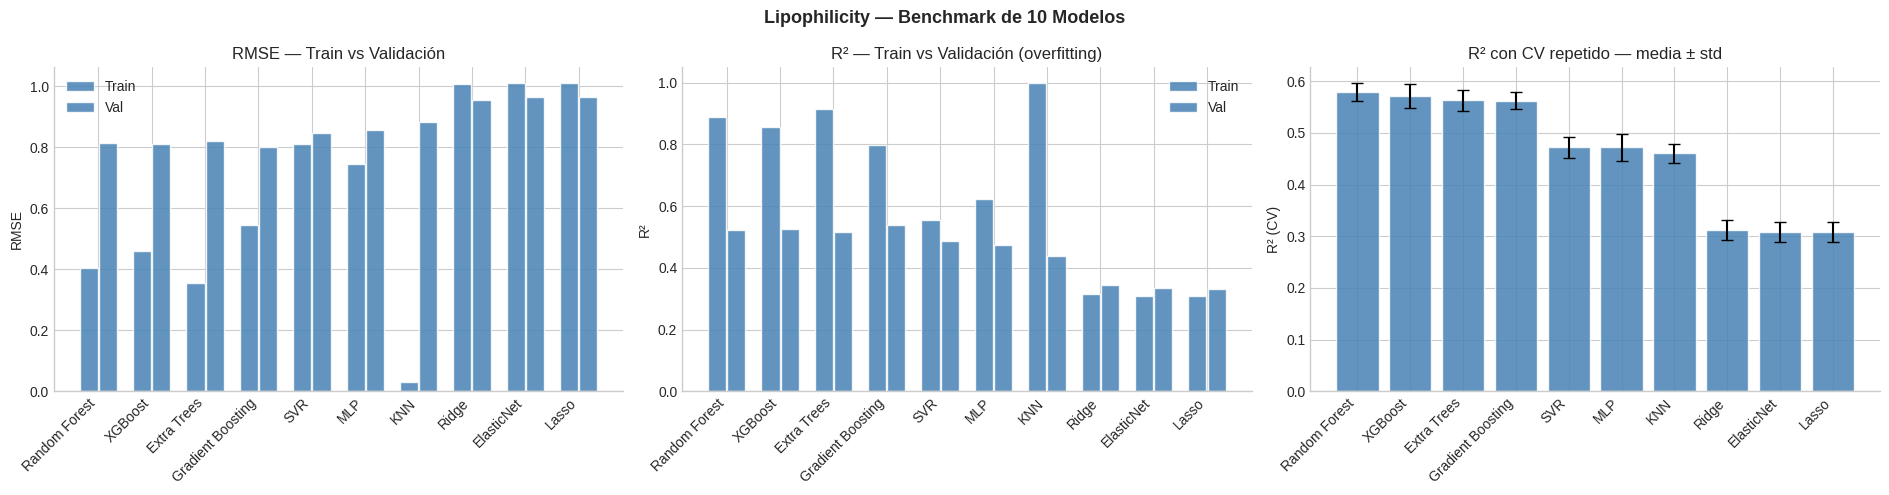

🏆 Mejor modelo (por R²_CV_mean): Random Forest  (0.5795 ± 0.0174)

📐 ¿Las diferencias son estadísticamente significativas?
📐 Test de Friedman:  χ² = 51.345   p = 0.0000
   → p < 0.05: hay evidencia de diferencias significativas entre AL MENOS dos modelos.

📊 Wilcoxon pareado — Random Forest (mejor) vs. cada uno de los demás (Bonferroni, α_ajustado=0.0056):
   Random Forest vs XGBoost              p=0.0938  ❌ no significativo
   Random Forest vs Extra Trees          p=0.0625  ❌ no significativo
   Random Forest vs Gradient Boosting    p=0.0312  ❌ no significativo
   Random Forest vs SVR                  p=0.0312  ❌ no significativo
   Random Forest vs MLP                  p=0.0312  ❌ no significativo
   Random Forest vs KNN                  p=0.0312  ❌ no significativo
   Random Forest vs Ridge                p=0.0312  ❌ no significativo
   Random Forest vs ElasticNet           p=0.0312  ❌ no significativo
   Random Forest vs Lasso                p=0.0312  ❌ no significativo


In [20]:
# ══════════════════════════════════════════════════════
#  CELDA 4.2 — Lipophilicity: tabla + gráficos + test estadístico
# ══════════════════════════════════════════════════════

tabla_lipo = df_eval_lipo.join(df_rob_lipo[['R2_CV_mean','R2_CV_std']]).sort_values('R2_CV_mean', ascending=False)
print('📊 Métricas — Lipophilicity:')
display(tabla_lipo.round(4)
        .style.background_gradient(cmap='RdYlGn', subset=['R2_val','R2_CV_mean'])
               .background_gradient(cmap='RdYlGn_r', subset=['RMSE_val'])
               .format('{:.4f}'))

mejor_lipo = plot_benchmark(df_eval_lipo, df_rob_lipo, 'Lipophilicity — Benchmark de 10 Modelos', 'steelblue')

print('\n📐 ¿Las diferencias son estadísticamente significativas?')
tabla_wilcoxon_lipo, p_friedman_lipo = test_estadistico(scores_lipo)

### 📌 ¿Qué aprendemos de Lipophilicity?
- Con scaffold split, comprueba si el R² sigue siendo alto o baja respecto a lo que veías antes
  con random split.
- Los ensembles (RF, ET, GBM, XGBoost) suelen capturar relaciones no lineales mejor que los lineales.
- Revisa la tabla de Wilcoxon: ¿el mejor modelo es *significativamente* mejor, o hay varios
  estadísticamente empatados?

---
## 🔹 4B — FreeSolv

In [21]:
# ══════════════════════════════════════════════════════
#  CELDA 4.3 — FreeSolv: split + búsqueda + evaluación + robustez
# ══════════════════════════════════════════════════════

print('💧 FREESOLV (ΔG hidratación)'); print('═'*50)
splits_freesolv = preparar_dataset(df_freesolv, random_state=RANDOM_STATE, metodo='scaffold')

print('\n🔎 Búsqueda de hiperparámetros (10 modelos)...')
mods_freesolv, df_busqueda_freesolv = buscar_hiperparametros(splits_freesolv)

print('\n📏 Evaluando en Train/Val...')
df_eval_freesolv = evaluar_modelos(splits_freesolv, mods_freesolv)

print('\n🔁 Robustez — CV repetido (extra importante: solo ~643 moléculas)...')
df_rob_freesolv, scores_freesolv = robustez_cv(splits_freesolv, mods_freesolv)

💧 FREESOLV (ΔG hidratación)
══════════════════════════════════════════════════
  División (scaffold):
    🟦 Train :   168 (26%)
    🟨 Val   :   320  (50%)
    🟥 Test  :   154  (24%)

🔎 Búsqueda de hiperparámetros (10 modelos)...
   ✓ Ridge                R²_CV=0.8464  (0.1s)
   ✓ Lasso                R²_CV=0.8435  (0.2s)
   ✓ ElasticNet           R²_CV=0.8464  (0.2s)
   ✓ KNN                  R²_CV=0.6252  (0.1s)
   ✓ SVR                  R²_CV=0.6810  (0.1s)
   ✓ Random Forest        R²_CV=0.6660  (13.0s)
   ✓ Extra Trees          R²_CV=0.7143  (7.9s)
   ✓ Gradient Boosting    R²_CV=0.7248  (7.8s)
   ✓ XGBoost              R²_CV=0.7162  (2.4s)
   ✓ MLP                  R²_CV=0.7670  (19.6s)

📏 Evaluando en Train/Val...

🔁 Robustez — CV repetido (extra importante: solo ~643 moléculas)...
   ✓ Ridge                R²_CV = 0.8748 ± 0.0213
   ✓ Lasso                R²_CV = 0.8679 ± 0.0269
   ✓ ElasticNet           R²_CV = 0.8770 ± 0.0214
   ✓ KNN                  R²_CV = 0.8416 ± 0.0333
 

📊 Métricas — FreeSolv:


,RMSE_train,MAE_train,R2_train,RMSE_val,MAE_val,R2_val,R2_CV_mean,R2_CV_std
Modelo,,,,,,,,
SVR,0.3184,0.1310,0.9950,2.1156,1.6062,0.5643,0.8942,0.0460
Gradient Boosting,0.5553,0.4134,0.9847,2.7090,2.0825,0.2857,0.8824,0.0211
XGBoost,0.6191,0.4527,0.9810,2.6313,2.1013,0.3260,0.8798,0.0275
ElasticNet,1.2452,0.9235,0.9231,4.0098,3.1984,-0.5650,0.8770,0.0214
Ridge,1.2446,0.9228,0.9232,4.0188,3.2138,-0.5721,0.8748,0.0213
Lasso,1.2399,0.9205,0.9238,3.3982,2.9171,-0.1240,0.8679,0.0269
MLP,1.0532,0.7710,0.9450,2.0109,1.5454,0.6064,0.8588,0.0512
Random Forest,1.0011,0.5597,0.9503,2.9795,2.0831,0.1359,0.8443,0.0450
KNN,0.0000,0.0000,1.0000,2.2819,1.8627,0.4932,0.8416,0.0333


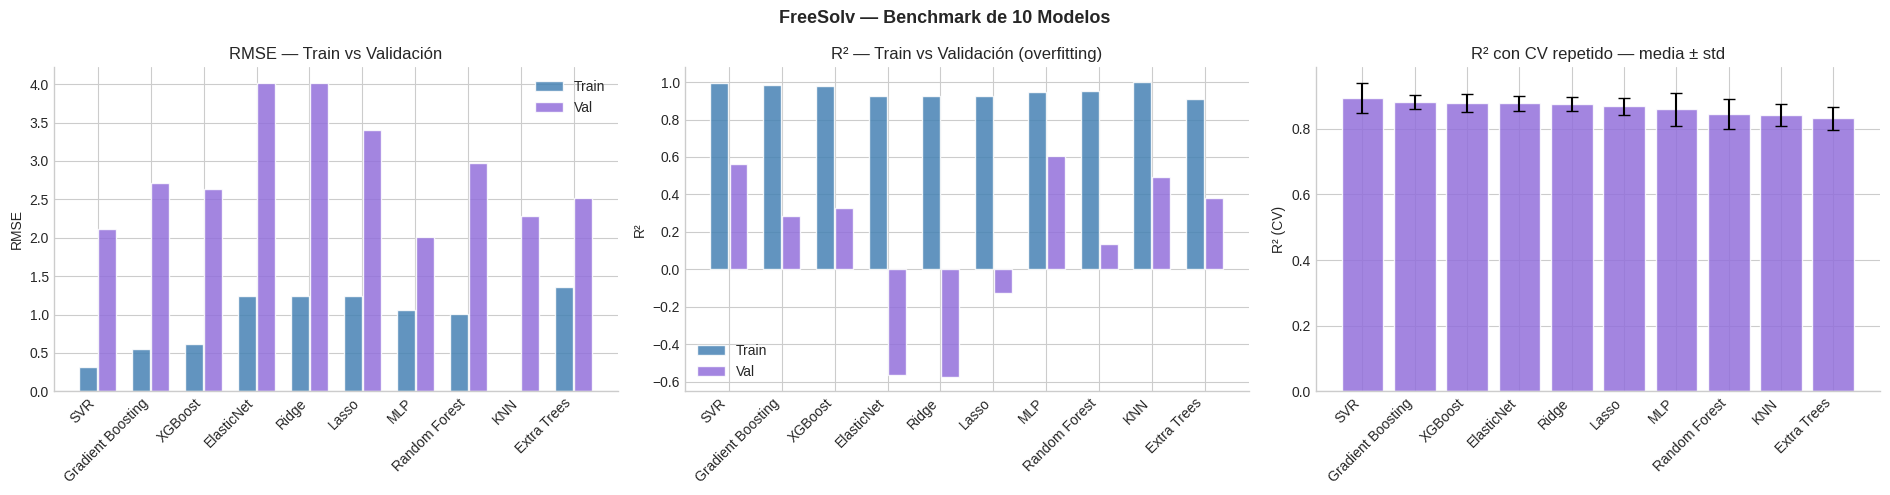

🏆 Mejor modelo (por R²_CV_mean): SVR  (0.8942 ± 0.0460)

📐 ¿Las diferencias son estadísticamente significativas?
📐 Test de Friedman:  χ² = 26.073   p = 0.0020
   → p < 0.05: hay evidencia de diferencias significativas entre AL MENOS dos modelos.

📊 Wilcoxon pareado — SVR (mejor) vs. cada uno de los demás (Bonferroni, α_ajustado=0.0056):
   SVR vs Gradient Boosting    p=0.6875  ❌ no significativo
   SVR vs XGBoost              p=0.4375  ❌ no significativo
   SVR vs ElasticNet           p=0.5625  ❌ no significativo
   SVR vs Ridge                p=0.4375  ❌ no significativo
   SVR vs Lasso                p=0.4375  ❌ no significativo
   SVR vs MLP                  p=0.3125  ❌ no significativo
   SVR vs Random Forest        p=0.0312  ❌ no significativo
   SVR vs KNN                  p=0.0938  ❌ no significativo
   SVR vs Extra Trees          p=0.0312  ❌ no significativo


In [22]:
# ══════════════════════════════════════════════════════
#  CELDA 4.4 — FreeSolv: tabla + gráficos + test estadístico
# ══════════════════════════════════════════════════════

tabla_freesolv = df_eval_freesolv.join(df_rob_freesolv[['R2_CV_mean','R2_CV_std']]).sort_values('R2_CV_mean', ascending=False)
print('📊 Métricas — FreeSolv:')
display(tabla_freesolv.round(4)
        .style.background_gradient(cmap='RdYlGn', subset=['R2_val','R2_CV_mean'])
               .background_gradient(cmap='RdYlGn_r', subset=['RMSE_val'])
               .format('{:.4f}'))

mejor_freesolv = plot_benchmark(df_eval_freesolv, df_rob_freesolv, 'FreeSolv — Benchmark de 10 Modelos', 'mediumpurple')

print('\n📐 ¿Las diferencias son estadísticamente significativas?')
tabla_wilcoxon_freesolv, p_friedman_freesolv = test_estadistico(scores_freesolv)

### 📌 ¿Qué aprendemos de FreeSolv?
- Con **pocos datos**, la desviación estándar del R²_CV suele ser mucho más grande que en
  Lipophilicity — mira los errorbars del tercer gráfico.
- Es probable que aquí el test de Friedman NO detecte diferencias significativas entre varios
  modelos: con tan pocas moléculas, es difícil distinguir el ruido de una ventaja real.

---
## 🔹 4C — LD50

In [23]:
# ══════════════════════════════════════════════════════
#  CELDA 4.5 — LD50: split + búsqueda + evaluación + robustez
#  ⚠️ El más lento: ~7,385 moléculas, SVR/XGBoost pueden tardar varios minutos
# ══════════════════════════════════════════════════════

print('☠️  LD50 ZHU (Toxicidad oral ratas)'); print('═'*50)
splits_ld50 = preparar_dataset(df_ld50, random_state=RANDOM_STATE, metodo='scaffold')

print('\n🔎 Búsqueda de hiperparámetros (10 modelos) — esto puede tardar varios minutos...')
mods_ld50, df_busqueda_ld50 = buscar_hiperparametros(splits_ld50)

print('\n📏 Evaluando en Train/Val...')
df_eval_ld50 = evaluar_modelos(splits_ld50, mods_ld50)

print('\n🔁 Robustez — CV repetido...')
df_rob_ld50, scores_ld50 = robustez_cv(splits_ld50, mods_ld50)

☠️  LD50 ZHU (Toxicidad oral ratas)
══════════════════════════════════════════════════
  División (scaffold):
    🟦 Train : 5,125 (69%)
    🟨 Val   : 1,110  (15%)
    🟥 Test  : 1,149  (16%)

🔎 Búsqueda de hiperparámetros (10 modelos) — esto puede tardar varios minutos...
   ✓ Ridge                R²_CV=0.1422  (0.1s)
   ✓ Lasso                R²_CV=0.1406  (1.2s)
   ✓ ElasticNet           R²_CV=0.1297  (1.6s)
   ✓ KNN                  R²_CV=0.2398  (2.4s)
   ✓ SVR                  R²_CV=0.3028  (99.9s)
   ✓ Random Forest        R²_CV=0.3150  (144.1s)
   ✓ Extra Trees          R²_CV=0.3198  (38.2s)
   ✓ Gradient Boosting    R²_CV=0.3347  (96.7s)
   ✓ XGBoost              R²_CV=0.3322  (14.5s)
   ✓ MLP                  R²_CV=0.2817  (93.0s)

📏 Evaluando en Train/Val...

🔁 Robustez — CV repetido...
   ✓ Ridge                R²_CV = 0.2265 ± 0.0113
   ✓ Lasso                R²_CV = 0.2249 ± 0.0118
   ✓ ElasticNet           R²_CV = 0.2268 ± 0.0124
   ✓ KNN                  R²_CV = 0.4260 ± 

📊 Métricas — LD50:


,RMSE_train,MAE_train,R2_train,RMSE_val,MAE_val,R2_val,R2_CV_mean,R2_CV_std
Modelo,,,,,,,,
Extra Trees,0.0561,0.0406,0.8877,0.1220,0.0948,0.2925,0.4952,0.0134
XGBoost,0.0633,0.0477,0.8570,0.1239,0.0959,0.2701,0.4939,0.0154
Random Forest,0.0599,0.0463,0.8722,0.1235,0.0963,0.2748,0.4757,0.0111
Gradient Boosting,0.0924,0.0720,0.6955,0.1254,0.0979,0.2527,0.4695,0.0106
SVR,0.1044,0.0730,0.6111,0.1303,0.1001,0.1924,0.4546,0.0185
KNN,0.0036,0.0002,0.9996,0.1273,0.0977,0.2303,0.4260,0.0164
MLP,0.1091,0.0834,0.5754,0.1306,0.1001,0.1894,0.4140,0.0107
ElasticNet,0.1448,0.1140,0.2526,0.1417,0.1121,0.0450,0.2268,0.0124
Ridge,0.1449,0.1142,0.2519,0.1415,0.1120,0.0478,0.2265,0.0113


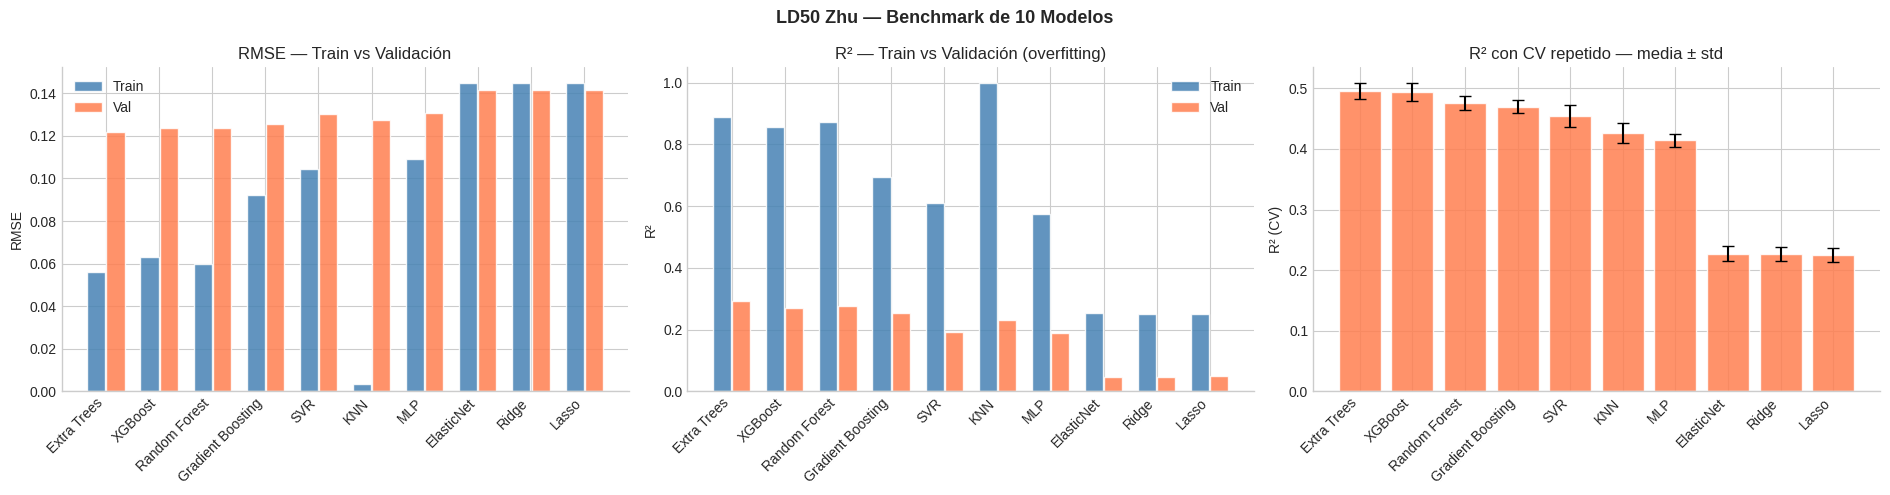

🏆 Mejor modelo (por R²_CV_mean): Extra Trees  (0.4952 ± 0.0134)

📐 ¿Las diferencias son estadísticamente significativas?
📐 Test de Friedman:  χ² = 52.618   p = 0.0000
   → p < 0.05: hay evidencia de diferencias significativas entre AL MENOS dos modelos.

📊 Wilcoxon pareado — Extra Trees (mejor) vs. cada uno de los demás (Bonferroni, α_ajustado=0.0056):
   Extra Trees vs XGBoost              p=0.4375  ❌ no significativo
   Extra Trees vs Random Forest        p=0.0312  ❌ no significativo
   Extra Trees vs Gradient Boosting    p=0.0312  ❌ no significativo
   Extra Trees vs SVR                  p=0.0312  ❌ no significativo
   Extra Trees vs KNN                  p=0.0312  ❌ no significativo
   Extra Trees vs MLP                  p=0.0312  ❌ no significativo
   Extra Trees vs ElasticNet           p=0.0312  ❌ no significativo
   Extra Trees vs Ridge                p=0.0312  ❌ no significativo
   Extra Trees vs Lasso                p=0.0312  ❌ no significativo


In [24]:
# ══════════════════════════════════════════════════════
#  CELDA 4.6 — LD50: tabla + gráficos + test estadístico
# ══════════════════════════════════════════════════════

tabla_ld50 = df_eval_ld50.join(df_rob_ld50[['R2_CV_mean','R2_CV_std']]).sort_values('R2_CV_mean', ascending=False)
print('📊 Métricas — LD50:')
display(tabla_ld50.round(4)
        .style.background_gradient(cmap='RdYlGn', subset=['R2_val','R2_CV_mean'])
               .background_gradient(cmap='RdYlGn_r', subset=['RMSE_val'])
               .format('{:.4f}'))

mejor_ld50 = plot_benchmark(df_eval_ld50, df_rob_ld50, 'LD50 Zhu — Benchmark de 10 Modelos', 'coral')

print('\n📐 ¿Las diferencias son estadísticamente significativas?')
tabla_wilcoxon_ld50, p_friedman_ld50 = test_estadistico(scores_ld50)

### 📌 ¿Qué aprendemos de LD50?
- El R² es menor que en LogP — esperado: la toxicidad depende de mecanismos biológicos complejos
  (metabolismo, unión a receptores, etc.) que los descriptores 2D no capturan del todo.
- Con ~7,385 moléculas y muchos scaffolds distintos, este es el dataset donde la búsqueda de
  hiperparámetros y los ensembles de boosting deberían mostrar más ventaja.

---

---
# 📓 PARTE 5 — Tabla Comparativa Estilo Artículo Científico
---

Consolidamos los resultados de los 3 datasets en una sola tabla, con **media ± desviación estándar**
(no un solo número), tal como se reportaría en la sección de resultados de un paper.

In [25]:
# ══════════════════════════════════════════════════════
#  CELDA 5.1 — Tabla consolidada de resultados
# ══════════════════════════════════════════════════════

def tabla_paper(df_rob, dataset_name):
    df = df_rob[['R2_CV_mean', 'R2_CV_std']].copy()
    df['R² (media ± std)'] = df.apply(lambda r: f"{r['R2_CV_mean']:.3f} ± {r['R2_CV_std']:.3f}", axis=1)
    df['Dataset'] = dataset_name
    return df[['Dataset', 'R² (media ± std)', 'R2_CV_mean']]

tabla_final = pd.concat([
    tabla_paper(df_rob_lipo,     'Lipophilicity'),
    tabla_paper(df_rob_freesolv, 'FreeSolv'),
    tabla_paper(df_rob_ld50,     'LD50_Zhu'),
])
tabla_final.index.name = 'Modelo'
tabla_final_ord = tabla_final.sort_values(['Dataset', 'R2_CV_mean'], ascending=[True, False])

print('📊 TABLA COMPARATIVA FINAL (estilo artículo)')
display(tabla_final_ord[['Dataset', 'R² (media ± std)']])

📊 TABLA COMPARATIVA FINAL (estilo artículo)


,Dataset,R² (media ± std)
Modelo,,
SVR,FreeSolv,0.894 ± 0.046
Gradient Boosting,FreeSolv,0.882 ± 0.021
XGBoost,FreeSolv,0.880 ± 0.028
ElasticNet,FreeSolv,0.877 ± 0.021
Ridge,FreeSolv,0.875 ± 0.021
Lasso,FreeSolv,0.868 ± 0.027
MLP,FreeSolv,0.859 ± 0.051
Random Forest,FreeSolv,0.844 ± 0.045
KNN,FreeSolv,0.842 ± 0.033


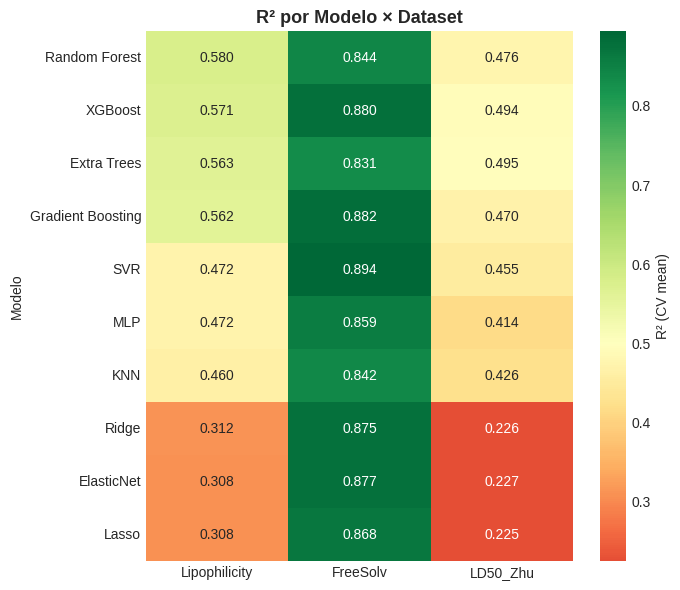

💡 Un modelo que sea top-3 en los 3 datasets es un candidato robusto de propósito general.
   Un modelo que solo gana en un dataset puede estar sobreajustado a las particularidades de ese caso.


In [26]:
# ══════════════════════════════════════════════════════
#  CELDA 5.2 — Heatmap R² por modelo x dataset
# ══════════════════════════════════════════════════════

pivot_r2 = pd.concat([
    df_rob_lipo['R2_CV_mean'].rename('Lipophilicity'),
    df_rob_freesolv['R2_CV_mean'].rename('FreeSolv'),
    df_rob_ld50['R2_CV_mean'].rename('LD50_Zhu'),
], axis=1)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(pivot_r2.sort_values('Lipophilicity', ascending=False), annot=True, fmt='.3f',
            cmap='RdYlGn', center=0.5, ax=ax, cbar_kws={'label': 'R² (CV mean)'})
ax.set_title('R² por Modelo × Dataset', fontweight='bold', fontsize=13)
plt.tight_layout(); plt.show()

print('💡 Un modelo que sea top-3 en los 3 datasets es un candidato robusto de propósito general.')
print('   Un modelo que solo gana en un dataset puede estar sobreajustado a las particularidades de ese caso.')

### 📌 Detección de overfitting (Train vs Validación)

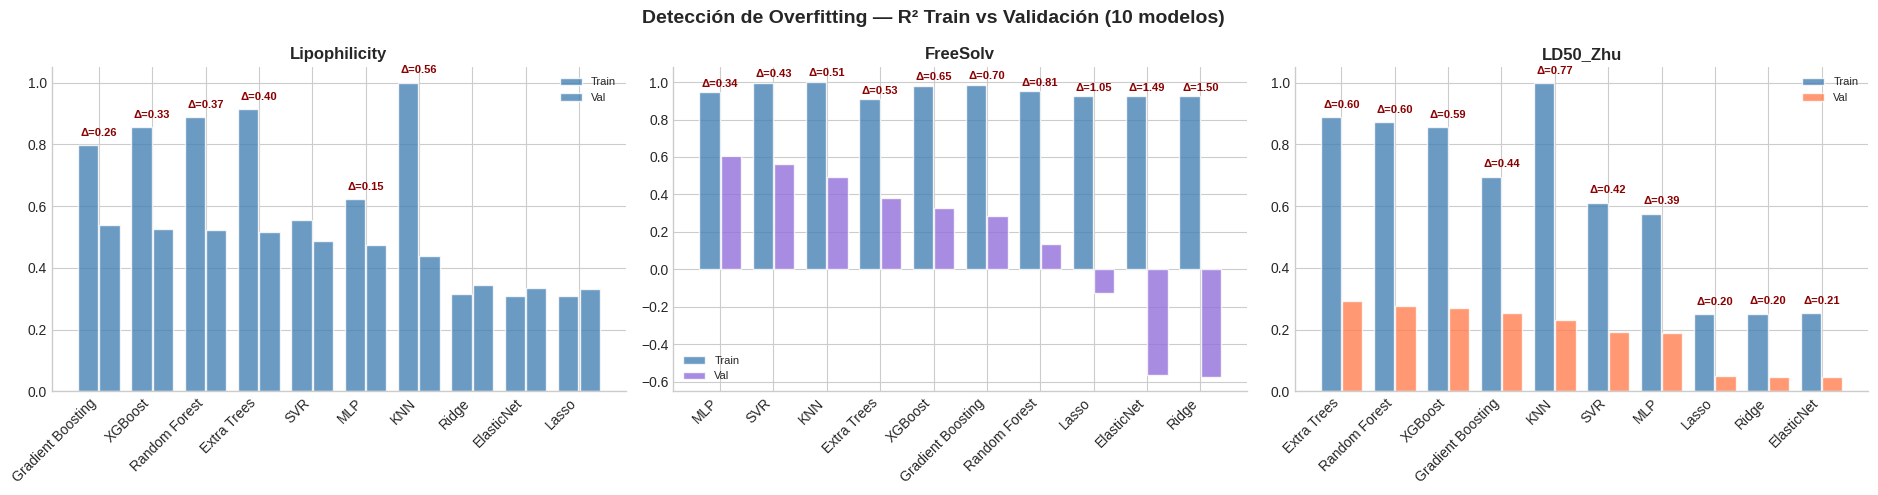

⚠️  Un gap grande (Δ) entre Train y Val es la señal clásica de overfitting: el modelo
   memoriza el train pero no generaliza. Los modelos flexibles (RF, ET, MLP) son los más propensos.


In [27]:
# ══════════════════════════════════════════════════════
#  CELDA 5.3 — Overfitting: gap Train vs Validación
# ══════════════════════════════════════════════════════

datasets_info = [
    (df_eval_lipo,     'Lipophilicity', 'steelblue'),
    (df_eval_freesolv, 'FreeSolv',      'mediumpurple'),
    (df_eval_ld50,     'LD50_Zhu',      'coral'),
]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
fig.suptitle('Detección de Overfitting — R² Train vs Validación (10 modelos)', fontweight='bold', fontsize=14)

for ax, (df_res, name, color) in zip(axes, datasets_info):
    df_sorted = df_res.sort_values('R2_val', ascending=False)
    x = np.arange(len(df_sorted))
    ax.bar(x-.2, df_sorted['R2_train'], .38, label='Train', color='steelblue', alpha=0.8, edgecolor='white')
    ax.bar(x+.2, df_sorted['R2_val'],   .38, label='Val',   color=color,       alpha=0.8, edgecolor='white')
    for i, (tr, vl) in enumerate(zip(df_sorted['R2_train'], df_sorted['R2_val'])):
        gap = tr - vl
        if gap > 0.10:
            ax.text(i, max(tr, vl)+0.03, f'Δ={gap:.2f}', ha='center', fontsize=8, color='darkred', fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(df_sorted.index, rotation=45, ha='right')
    ax.set_title(name, fontweight='bold'); ax.legend(fontsize=8)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.tight_layout(); plt.show()
print('⚠️  Un gap grande (Δ) entre Train y Val es la señal clásica de overfitting: el modelo')
print('   memoriza el train pero no generaliza. Los modelos flexibles (RF, ET, MLP) son los más propensos.')

---
# 📔 PARTE 6 — Interpretabilidad con SHAP
---

Aplicamos SHAP al **mejor modelo de cada dataset** para entender qué descriptores pesan más en
sus predicciones.

🏆 Mejor modelo Lipophilicity: Random Forest


PermutationExplainer explainer: 101it [02:11,  1.37s/it]


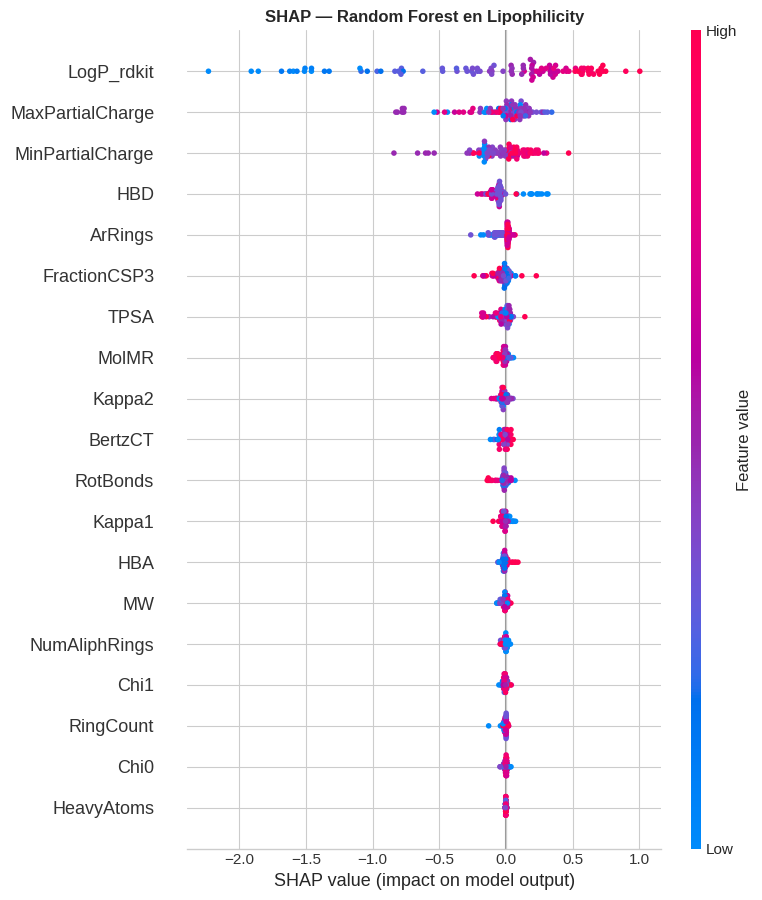

📋 Top 5 descriptores por |SHAP| promedio:
LogP_rdkit          0.5863
MaxPartialCharge    0.1704
MinPartialCharge    0.1530
HBD                 0.0879
ArRings             0.0423


In [28]:
# ══════════════════════════════════════════════════════
#  CELDA 6.1 — SHAP para el mejor modelo de cada dataset
# ══════════════════════════════════════════════════════

print(f'🏆 Mejor modelo Lipophilicity: {mejor_lipo}')
_ = shap_interpretabilidad(
    mods_lipo[mejor_lipo], splits_lipo['X_train'], splits_lipo['X_val'],
    FEATURE_NAMES, f'SHAP — {mejor_lipo} en Lipophilicity')

🏆 Mejor modelo FreeSolv: SVR


PermutationExplainer explainer: 101it [00:30,  2.21it/s]


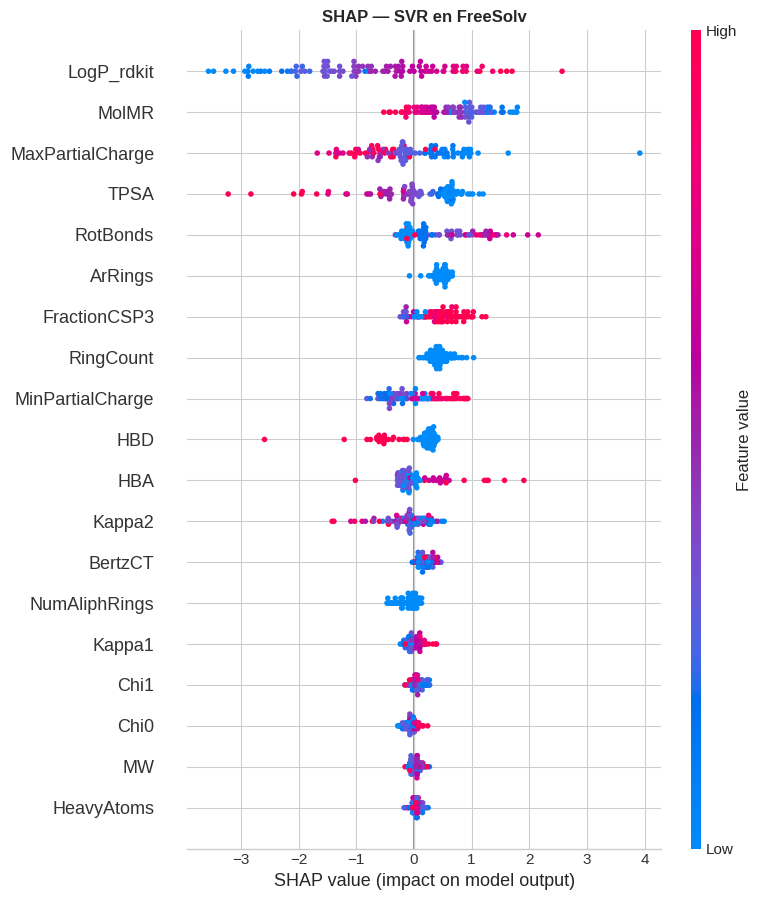

📋 Top 5 descriptores por |SHAP| promedio:
LogP_rdkit          1.2283
MolMR               0.7280
MaxPartialCharge    0.6166
TPSA                0.6074
RotBonds            0.5352


In [29]:
print(f'🏆 Mejor modelo FreeSolv: {mejor_freesolv}')
_ = shap_interpretabilidad(
    mods_freesolv[mejor_freesolv], splits_freesolv['X_train'], splits_freesolv['X_val'],
    FEATURE_NAMES, f'SHAP — {mejor_freesolv} en FreeSolv')

🏆 Mejor modelo LD50: Extra Trees


PermutationExplainer explainer: 101it [02:11,  1.41s/it]


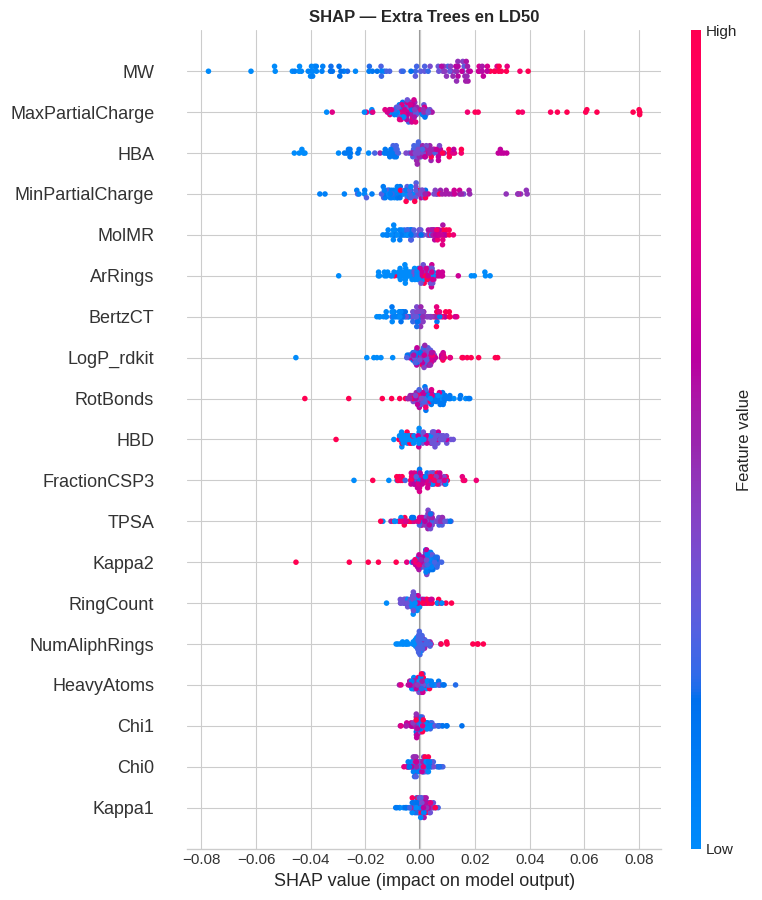

📋 Top 5 descriptores por |SHAP| promedio:
MW                  0.0226
MaxPartialCharge    0.0132
HBA                 0.0110
MinPartialCharge    0.0107
MolMR               0.0060


In [30]:
print(f'🏆 Mejor modelo LD50: {mejor_ld50}')
_ = shap_interpretabilidad(
    mods_ld50[mejor_ld50], splits_ld50['X_train'], splits_ld50['X_val'],
    FEATURE_NAMES, f'SHAP — {mejor_ld50} en LD50')

### 📌 ¿Qué aprendemos de SHAP?
- Compara el ranking de importancia SHAP con el de correlación de Pearson que viste en la Parte 1 (EDA).
  ¿Coinciden los descriptores más importantes?
- SHAP captura **interacciones y no linealidades** que la correlación simple no puede ver — por eso
  puede diferir del ranking de EDA, especialmente en modelos de árboles.

---

---
# 📕 PARTE 7 — Evaluación Final en Test
---

> ## ⚠️ REGLA DE ORO
> El conjunto **Test** se usa **UNA SOLA VEZ**, aquí al final.
> Nunca antes. Nunca para ajustar hiperparámetros. Nunca para elegir modelos.
> Esta sección simula lo que publicarías como resultado final de tu artículo.

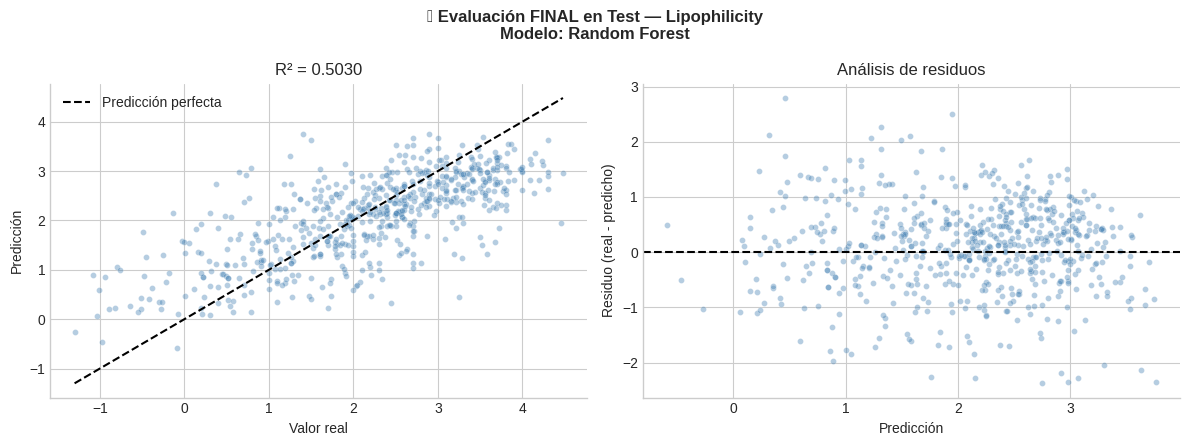

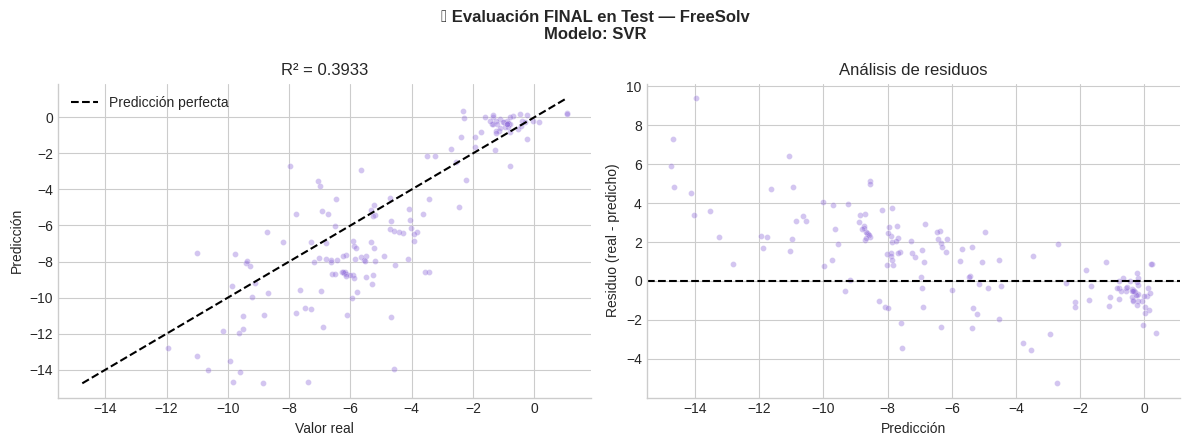

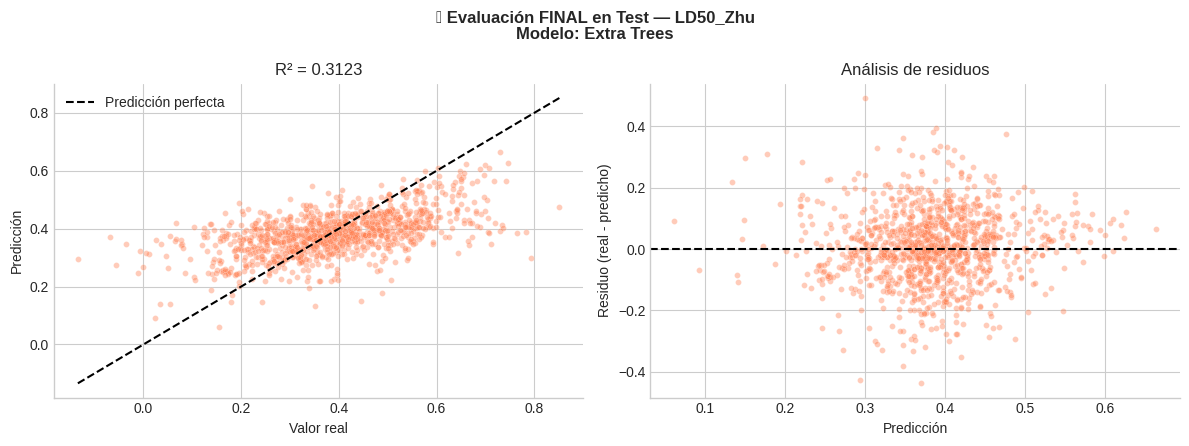

In [31]:
# ══════════════════════════════════════════════════════
#  CELDA 7.1 — Evaluación final en Test para el mejor modelo de cada dataset
# ══════════════════════════════════════════════════════

def evaluar_en_test(splits, modelo, nombre_modelo, nombre_dataset, color):
    y_pred_test = modelo.predict(splits['X_test'])
    rmse = np.sqrt(mean_squared_error(splits['y_test'], y_pred_test))
    mae  = mean_absolute_error(splits['y_test'], y_pred_test)
    r2   = r2_score(splits['y_test'], y_pred_test)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    fig.suptitle(f'🟥 Evaluación FINAL en Test — {nombre_dataset}\nModelo: {nombre_modelo}',
                 fontweight='bold', fontsize=12)

    ax = axes[0]
    ax.scatter(splits['y_test'], y_pred_test, alpha=0.4, s=18, color=color, edgecolor='white', linewidth=0.3)
    lims = [min(splits['y_test'].min(), y_pred_test.min()), max(splits['y_test'].max(), y_pred_test.max())]
    ax.plot(lims, lims, 'k--', lw=1.5, label='Predicción perfecta')
    ax.set_xlabel('Valor real'); ax.set_ylabel('Predicción'); ax.set_title(f'R² = {r2:.4f}')
    ax.legend(); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    ax = axes[1]
    residuos = splits['y_test'] - y_pred_test
    ax.scatter(y_pred_test, residuos, alpha=0.4, s=18, color=color, edgecolor='white', linewidth=0.3)
    ax.axhline(0, color='black', linestyle='--', lw=1.5)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Residuo (real - predicho)'); ax.set_title('Análisis de residuos')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

    plt.tight_layout(); plt.show()
    return {'Dataset': nombre_dataset, 'Modelo': nombre_modelo, 'RMSE_test': rmse, 'MAE_test': mae, 'R2_test': r2}


res_test_lipo     = evaluar_en_test(splits_lipo,     mods_lipo[mejor_lipo],         mejor_lipo,     'Lipophilicity', 'steelblue')
res_test_freesolv = evaluar_en_test(splits_freesolv, mods_freesolv[mejor_freesolv], mejor_freesolv, 'FreeSolv',      'mediumpurple')
res_test_ld50     = evaluar_en_test(splits_ld50,     mods_ld50[mejor_ld50],         mejor_ld50,     'LD50_Zhu',      'coral')

In [32]:
# ══════════════════════════════════════════════════════
#  CELDA 7.2 — Tabla de resultados finales
# ══════════════════════════════════════════════════════

df_test_final = pd.DataFrame([res_test_lipo, res_test_freesolv, res_test_ld50]).set_index('Dataset')

print('🏁 RESULTADOS FINALES EN TEST')
print('='*60)
display(df_test_final.round(4)
        .style.background_gradient(cmap='RdYlGn', subset=['R2_test'])
               .background_gradient(cmap='RdYlGn_r', subset=['RMSE_test','MAE_test'])
               .format('{:.4f}', subset=['RMSE_test','MAE_test','R2_test']))

print('\n📌 Interpretación:')
print('   RMSE y MAE están en las mismas unidades que la propiedad predicha.')
print('   Compara R2_test contra R2_CV_mean de la Parte 4-5: si son parecidos, el modelo')
print('   generaliza de forma consistente. Si R2_test es mucho menor, revisa posible')
print('   sobreajuste al conjunto de validación durante la búsqueda de hiperparámetros.')

🏁 RESULTADOS FINALES EN TEST


,Modelo,RMSE_test,MAE_test,R2_test
Dataset,,,,
Lipophilicity,Random Forest,0.8177,0.6417,0.5030
FreeSolv,SVR,2.3999,1.8560,0.3933
LD50_Zhu,Extra Trees,0.1189,0.0907,0.3123



📌 Interpretación:
   RMSE y MAE están en las mismas unidades que la propiedad predicha.
   Compara R2_test contra R2_CV_mean de la Parte 4-5: si son parecidos, el modelo
   generaliza de forma consistente. Si R2_test es mucho menor, revisa posible
   sobreajuste al conjunto de validación durante la búsqueda de hiperparámetros.


---
# 📗 PARTE 8 — Predicción con tu Propia Molécula
---

Ingresa cualquier molécula en SMILES y obtén las 3 predicciones (LogP, ΔG de hidratación, y
log₁₀(LD50)) usando los mejores modelos encontrados en el benchmark.

**¿Dónde obtener SMILES?**
- [PubChem](https://pubchem.ncbi.nlm.nih.gov/) → busca → pestaña 'Canonical SMILES'
- [MolView](https://molview.org/) → dibuja → Tools → SMILES

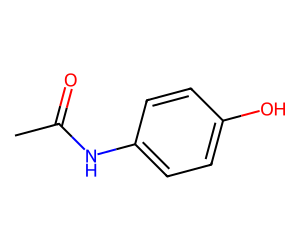

🧪 Predicciones para: Paracetamol  (CC(=O)Nc1ccc(O)cc1)
──────────────────────────────────────────────────
  LogP (lipofilicidad)      : 0.66   [modelo: Random Forest]
  ΔG hidratación (kcal/mol) : -14.20   [modelo: SVR]
  LD50 estimado (mg/kg)     : 1.9   [modelo: Extra Trees]
    (log₁₀(LD50) = 0.28)


In [33]:
# ══════════════════════════════════════════════════════
#  CELDA 8.1 — Predicción interactiva
#  ✏️ MODIFICA LAS DOS LÍNEAS DE ABAJO
# ══════════════════════════════════════════════════════

# ─── Ejemplos para probar ─────────────────────────────────────
# Paracetamol : CC(=O)Nc1ccc(O)cc1
# Ibuprofeno  : CC(C)Cc1ccc(cc1)C(C)C(=O)O
# Cafeína     : Cn1cnc2c1c(=O)n(c(=O)n2C)C
# Benceno     : c1ccccc1
# Etanol      : CCO
# Colesterol  : CC(C)CCCC(C)C1CCC2C1(CCC3C2CC=C4C3(CCC(C4)O)C)C
# ─────────────────────────────────────────────────────────────

MI_SMILES = 'CC(=O)Nc1ccc(O)cc1'    # ← CAMBIA AQUÍ
MI_NOMBRE = 'Paracetamol'            # ← Y AQUÍ

# ─── Predicción ──────────────────────────────
desc = calcular_descriptores(MI_SMILES)
if desc is None:
    print(f'❌ SMILES inválido: {MI_SMILES}')
else:
    x_new = np.array([[desc[f] for f in FEATURE_NAMES]])

    x_lipo_sc     = splits_lipo['scaler'].transform(x_new)
    x_freesolv_sc = splits_freesolv['scaler'].transform(x_new)
    x_ld50_sc     = splits_ld50['scaler'].transform(x_new)

    pred_logp     = mods_lipo[mejor_lipo].predict(x_lipo_sc)[0]
    pred_freesolv = mods_freesolv[mejor_freesolv].predict(x_freesolv_sc)[0]
    pred_ld50_log = mods_ld50[mejor_ld50].predict(x_ld50_sc)[0]
    pred_ld50_mgkg = 10 ** pred_ld50_log

    mol = Chem.MolFromSmiles(MI_SMILES)
    display(Draw.MolToImage(mol, size=(300, 250)))

    print(f'🧪 Predicciones para: {MI_NOMBRE}  ({MI_SMILES})')
    print('─'*50)
    print(f'  LogP (lipofilicidad)      : {pred_logp:.2f}   [modelo: {mejor_lipo}]')
    print(f'  ΔG hidratación (kcal/mol) : {pred_freesolv:.2f}   [modelo: {mejor_freesolv}]')
    print(f'  LD50 estimado (mg/kg)     : {pred_ld50_mgkg:,.1f}   [modelo: {mejor_ld50}]')
    print(f'    (log₁₀(LD50) = {pred_ld50_log:.2f})')

---
# 📝 PARTE 9 — Ejercicios Propuestos
---

### ✏️ Ejercicio 1 — Importancia de Features (Random Forest vs. SHAP)

El código está completo. Ejecútalo y responde las preguntas.

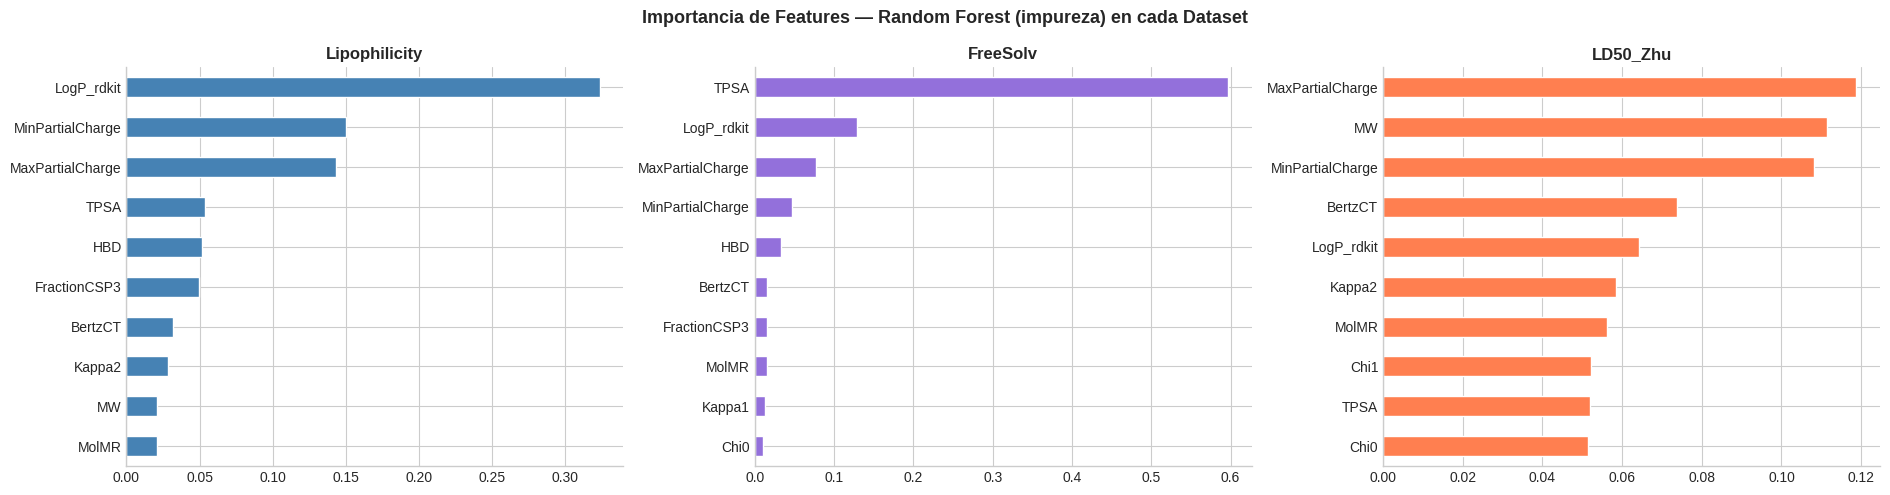

❓ Preguntas:
   1. ¿La importancia por impureza de Random Forest coincide con el ranking de SHAP
      que calculaste en la Parte 6 para el MEJOR modelo de cada dataset?
   2. Si Random Forest no fue el mejor modelo en algún dataset, ¿por qué crees que
      igual es útil mirar su importancia de features?
   3. ¿Qué descriptor aparece consistentemente importante en los 3 datasets? ¿Por qué
      tendría sentido químicamente?


In [34]:
# ══════════════════════════════════════════════════════
#  EJERCICIO 1 — Importancia de Features: Random Forest (impureza) vs SHAP
# ══════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
fig.suptitle('Importancia de Features — Random Forest (impureza) en cada Dataset',
             fontweight='bold', fontsize=13)

modelos_rf = [mods_lipo['Random Forest'], mods_freesolv['Random Forest'], mods_ld50['Random Forest']]
nombres_ds = ['Lipophilicity', 'FreeSolv', 'LD50_Zhu']
colores    = ['steelblue', 'mediumpurple', 'coral']

for ax, rf_model, name, color in zip(axes, modelos_rf, nombres_ds, colores):
    imp = pd.Series(rf_model.feature_importances_, index=FEATURE_NAMES).sort_values()
    imp.tail(10).plot(kind='barh', ax=ax, color=color, edgecolor='white')
    ax.set_title(name, fontweight='bold')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.tight_layout(); plt.show()

print('❓ Preguntas:')
print('   1. ¿La importancia por impureza de Random Forest coincide con el ranking de SHAP')
print('      que calculaste en la Parte 6 para el MEJOR modelo de cada dataset?')
print('   2. Si Random Forest no fue el mejor modelo en algún dataset, ¿por qué crees que')
print('      igual es útil mirar su importancia de features?')
print('   3. ¿Qué descriptor aparece consistentemente importante en los 3 datasets? ¿Por qué')
print('      tendría sentido químicamente?')

### ✏️ Ejercicio 2 — Curva de Aprendizaje

¿Desde cuántas moléculas se estabiliza el R² de validación? Usamos el mejor modelo de Lipophilicity.

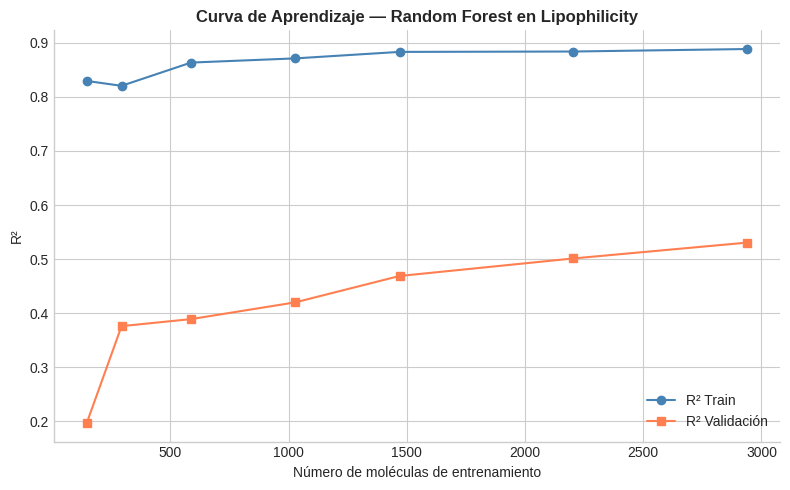

❓ Preguntas:
   1. ¿Desde cuántas moléculas el R² de validación se estabiliza?
   2. ¿Por qué R²_train empieza muy alto con pocas moléculas?
   3. ¿Qué implica esto para FreeSolv, que solo tiene ~643 moléculas?


In [35]:
# ══════════════════════════════════════════════════════
#  EJERCICIO 2 — Curva de Aprendizaje en Lipophilicity
# ══════════════════════════════════════════════════════

fracciones = [0.05, 0.10, 0.20, 0.35, 0.50, 0.75, 1.00]
r2_tr_curve, r2_vl_curve, n_mols = [], [], []

for frac in fracciones:
    n   = max(10, int(frac * len(splits_lipo['X_train'])))
    idx = np.random.RandomState(RANDOM_STATE).choice(len(splits_lipo['X_train']), n, replace=False)
    m   = clone(mods_lipo[mejor_lipo])
    m.fit(splits_lipo['X_train'][idx], splits_lipo['y_train'][idx])
    r2_tr_curve.append(r2_score(splits_lipo['y_train'][idx], m.predict(splits_lipo['X_train'][idx])))
    r2_vl_curve.append(r2_score(splits_lipo['y_val'], m.predict(splits_lipo['X_val'])))
    n_mols.append(n)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(n_mols, r2_tr_curve, 'o-', label='R² Train', color='steelblue')
ax.plot(n_mols, r2_vl_curve, 's-', label='R² Validación', color='coral')
ax.set_xlabel('Número de moléculas de entrenamiento'); ax.set_ylabel('R²')
ax.set_title(f'Curva de Aprendizaje — {mejor_lipo} en Lipophilicity', fontweight='bold')
ax.legend(); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

print('❓ Preguntas:')
print('   1. ¿Desde cuántas moléculas el R² de validación se estabiliza?')
print('   2. ¿Por qué R²_train empieza muy alto con pocas moléculas?')
print('   3. ¿Qué implica esto para FreeSolv, que solo tiene ~643 moléculas?')

### ✏️ Ejercicio 3 — Agregar un Nuevo Descriptor

In [36]:
# ══════════════════════════════════════════════════════
#  EJERCICIO 3 — Agregar NumHeteroatoms a FreeSolv
#  ¿Mejora el R² al agregar información sobre heteroátomos?
# ══════════════════════════════════════════════════════

FEATURE_NAMES_EXT = FEATURE_NAMES + ['NumHeteroatoms']

print('⏳ Recalculando descriptores extendidos para FreeSolv...')
rows_ext, targets_ext, scaffolds_ext = [], [], []
for smi, tgt in zip(df_freesolv_raw['smiles'], df_freesolv_raw['expt']):
    desc = calcular_descriptores(str(smi))
    if desc is not None and not np.isnan(float(tgt)):
        mol = Chem.MolFromSmiles(str(smi))
        desc['NumHeteroatoms'] = Descriptors.NumHeteroatoms(mol)
        rows_ext.append(desc)
        targets_ext.append(float(tgt))
        scaffolds_ext.append(obtener_scaffold(str(smi)))

df_ext = pd.DataFrame(rows_ext)
df_ext['target'] = targets_ext
df_ext['scaffold'] = scaffolds_ext
df_clean_ext = df_ext[FEATURE_NAMES_EXT + ['target', 'scaffold']].dropna().reset_index(drop=True)

tr_idx, vl_idx, ts_idx = scaffold_split(df_clean_ext, random_state=RANDOM_STATE)
X_ext, y_ext = df_clean_ext[FEATURE_NAMES_EXT].values, df_clean_ext['target'].values
sc_e = StandardScaler()
X_tr_sc = sc_e.fit_transform(X_ext[tr_idx])
X_vl_sc = sc_e.transform(X_ext[vl_idx])

mod_ext = clone(mods_freesolv[mejor_freesolv])
mod_ext.fit(X_tr_sc, y_ext[tr_idx])
r2_ext  = r2_score(y_ext[vl_idx], mod_ext.predict(X_vl_sc))
r2_base = df_eval_freesolv.loc[mejor_freesolv, 'R2_val']

print(f'\n📊 FreeSolv — {mejor_freesolv}:')
print(f'   R² sin NumHeteroatoms : {r2_base:.4f}')
print(f'   R² con NumHeteroatoms : {r2_ext:.4f}')
mejora = r2_ext - r2_base
print(f'   Diferencia: {mejora:+.4f}  {"✅ mejora" if mejora > 0 else "❌ no mejora"}')
print('\n❓ ¿Por qué crees que sí/no mejora? ¿Qué otro descriptor agregarías?')

⏳ Recalculando descriptores extendidos para FreeSolv...

📊 FreeSolv — SVR:
   R² sin NumHeteroatoms : 0.5643
   R² con NumHeteroatoms : 0.5555
   Diferencia: -0.0088  ❌ no mejora

❓ ¿Por qué crees que sí/no mejora? ¿Qué otro descriptor agregarías?


### ✏️ Ejercicio 4 — Desafío Abierto

Elige UNA opción y escribe tu código en la celda de abajo.

In [37]:
# ══════════════════════════════════════════════════════
#  EJERCICIO 4 — DESAFÍO ABIERTO
# ══════════════════════════════════════════════════════

# ─── OPCIÓN A: Reducir el espacio de búsqueda de un modelo ─────
# Elige un modelo (ej. XGBoost) y prueba reducir/expandir su grid de
# hiperparámetros en get_modelos_y_grids(). ¿Cambia el ranking final?

# ─── OPCIÓN B: Aplicar el pipeline completo a ESOL (solubilidad) ──
# URL = 'https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv'
# Columna SMILES: 'smiles' | Target: 'measured log solubility in mols per litre'
# Usa smiles_list_to_features(), preparar_dataset(), buscar_hiperparametros(),
# evaluar_modelos() y robustez_cv() — el pipeline ya está listo para reutilizar.

# ─── OPCIÓN C: Análisis de errores en LD50 ──────────────────────
# Encuentra las 5 moléculas con mayor error de predicción en el TEST de LD50.
# Pista:
#   y_pred_ts = mods_ld50[mejor_ld50].predict(splits_ld50['X_test'])
#   errores = np.abs(splits_ld50['y_test'] - y_pred_ts)
#   top5_idx = np.argsort(errores)[-5:]
# ¿Tienen algo en común esas moléculas? ¿Qué dice SHAP sobre ellas específicamente?

# ─── OPCIÓN D: Repetir el benchmark con random split ────────────
# Vuelve a correr la Parte 4 completa pero con metodo='random' en preparar_dataset().
# Compara la tabla final con la de scaffold split. ¿Cuánto se infla el R²?

# ─────────────────────────────────────────────────────────────────
# TU CÓDIGO AQUÍ:



print('💡 Escoge tu opción y borra este print cuando termines')

💡 Escoge tu opción y borra este print cuando termines


---
# 🏁 Resumen del Laboratorio
---

## Lo que practicaste

| Concepto | Dónde |
|----------|-------|
| SMILES y visualización | Parte 0 |
| Cálculo de descriptores con RDKit | Parte 0 — `calcular_descriptores()` |
| Scaffold de Bemis-Murcko | Parte 0 — `obtener_scaffold()` |
| Análisis exploratorio EDA | Parte 1 — distribuciones, correlaciones, diversidad de scaffolds |
| Scaffold split vs random split | Parte 2 — `scaffold_split()`, comparación empírica |
| División Train/Val/Test | Parte 2 — `preparar_dataset()` |
| Normalización correcta | Parte 2 — StandardScaler solo en Train |
| 10 modelos de 5 familias distintas | Parte 3 — `get_modelos_y_grids()` |
| Búsqueda de hiperparámetros | Parte 3 — `buscar_hiperparametros()` (RandomizedSearchCV) |
| Robustez vía CV repetido multi-semilla | Parte 3 — `robustez_cv()` |
| Benchmark completo en 3 datasets | Parte 4 |
| Tabla estilo artículo (media ± std) | Parte 5 |
| Tests estadísticos (Friedman + Wilcoxon) | Parte 3/4 — `test_estadistico()` |
| Interpretabilidad con SHAP | Parte 6 |
| Evaluación final en Test | Parte 7 — una sola vez |
| Predicción de nuevas moléculas | Parte 8 |

## Conclusiones clave

1. **El scaffold split da una medida más honesta de generalización** que el split aleatorio —
   siempre repórtalo cuando trabajes con moléculas.
2. **No hay un modelo ganador universal**: revisa el heatmap de la Parte 5 para ver si algún modelo
   fue consistentemente competitivo en los 3 datasets, o si el "mejor modelo" cambió según el problema.
3. **Reporta incertidumbre, no solo un número**: la media ± desviación estándar (y el test de
   Friedman/Wilcoxon) te dicen si una diferencia de R² es real o ruido.
4. **FreeSolv** ilustra cómo el tamaño del dataset afecta la estabilidad de las métricas — con
   pocos datos, la incertidumbre es mucho mayor.
5. **LD50** es el más difícil — la toxicidad depende de mecanismos biológicos no capturables
   completamente con descriptores 2D.
6. **SHAP** te permite ir más allá de "qué modelo ganó" a "por qué ganó" — fundamental para que un
   resultado de ML sea útil y creíble en cheminformática.

## Próximos pasos

- 🔬 **Morgan Fingerprints** — representación binaria más rica que los descriptores continuos
- 🧠 **Graph Neural Networks** — aprenden directamente del grafo molecular (siguiente nivel más allá de este laboratorio)
- 🎯 **Multi-task learning** — predecir varias propiedades simultáneamente
- 📈 **Optuna / Bayesian Optimization** — alternativa más eficiente a `RandomizedSearchCV` para la búsqueda de hiperparámetros
- 🧬 **Applicability domain** — cuantificar en qué región del espacio químico el modelo es confiable

## Referencias

- Bemis, G. W.; Murcko, M. A. *The Properties of Known Drugs. 1. Molecular Frameworks.* J. Med. Chem. **1996**, 39, 2887–2893.
- Mobley, D. L.; Guthrie, J. P. *FreeSolv: a database of experimental and calculated hydration free energies.* J. Comput. Aided Mol. Des. **2014**, 28, 711–720.
- Zhu, H. et al. *Quantitative Structure-Activity Relationship Modeling of Rat Acute Toxicity by Oral Exposure.* Chem. Res. Toxicol. **2009**, 22, 1913–1921.
- Lundberg, S. M.; Lee, S.-I. *A Unified Approach to Interpreting Model Predictions (SHAP).* NeurIPS **2017**.
- Chen, T.; Guestrin, C. *XGBoost: A Scalable Tree Boosting System.* KDD **2016**.
- Wu, Z. et al. *MoleculeNet: A Benchmark for Molecular Machine Learning.* Chem. Sci. **2018**, 9, 513–530.
- Pedregosa, F. et al. *Scikit-learn: Machine Learning in Python.* JMLR **2011**, 12, 2825–2830.

---
*Laboratorio desarrollado con: RDKit · Scikit-learn · XGBoost · SHAP · MoleculeNet · TDC · Hugging Face*

*Datasets: Lipophilicity (AstraZeneca/MoleculeNet) · FreeSolv/SAMPL (Mobley & Guthrie) · LD50_Zhu (Zhu et al. 2009)*